# Modelagem Preditiva de Decisões Judiciais nas Varas de Relações de Consumo da Comarca de Salvador com Aprendizado de Máquina

Este notebook consolida todo o pipeline de jurimetria preditiva do trabalho de conclusão de curso — desde a **Carga e Inspeção dos Dados Primários do DataJud**, **Análise Exploratória de Dados (EDA)**, **Higienização e Filtragem de Mérito**, **Engenharia de Atributos de Domínio Jurídico**, até a **Modelagem Preditiva Supervisionada e Validação Temporal Rígida** aplicada às 20 Varas de Relações de Consumo da Comarca de Salvador (TJBA).

---

### 📌 Fundamentação Teórica e Metodológica do Trabalho:
1. **Prevenção Rigorosa de Data Leakage Temporal:** A codificação das variáveis categóricas de alta cardinalidade (*Bayesian Target Encoding*) é calculada estritamente via **Out-Of-Fold (OOF) com Janela Expansiva Temporal (`TimeSeriesSplit`)** no conjunto de treino (2020–2023), impedindo que desfechos futuros contaminem o passado.
2. **Atributos de Domínio Jurídico Tabular:** Marcadores institucionais do Processo Civil brasileiro (`is_recesso_forense`, `trimestre`, `dia_semana_num`, `is_fim_ano`, `is_inicio_ano`), otimizados para particionamento ortogonal em algoritmos baseados em árvores (Random Forest e XGBoost) e adequadamente binarizados via *One-Hot Encoding* para o modelo linear de Regressão Logística.
3. **Validação Temporal Rígida (2020–2023 vs. 2024):** Treinamento exclusivo com processos de 2020 a 2023 (78.568 casos) e avaliação realista no futuro com dados de teste cego de 2024 (12.889 casos).
4. **Otimização do Limiar de Decisão (*Threshold Tuning*):** Ajuste do limiar ótimo de corte probabilístico (calibrado via Curva Precision-Recall) para maximizar o equilíbrio entre Precisão e Recall.
5. **Interpretabilidade e Parcimônia (Navalha de Ockham):** Comparação estatística com intervalos de confiança a 95% via *Bootstrapping*, priorizando a explicabilidade jurídica (*Explainable AI* / XAI) na escolha do modelo final.


In [35]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold, TimeSeriesSplit
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
)


sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 150
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

print(f"Ambiente inicializado com sucesso. Versao Pandas: {pd.__version__}")


Ambiente inicializado com sucesso. Versao Pandas: 2.3.3


## 1. Análise Exploratória de Dados (EDA) e Carga da Base Bruta (`df_bruto`)

Carregamos o dataset primário oficial (`dataset_relacoes_consumo.csv`), extraído diretamente da API Pública do DataJud (CNJ), contendo 199.105 processos distribuídos entre 2020 e 2024 nas Varas de Relações de Consumo de Salvador.

### 1.0 Glossário das Colunas do DataFrame Bruto (`df_bruto`)

A tabela abaixo descreve o significado e a função de cada uma das 6 colunas originais do conjunto de dados primário extraído da API Pública do DataJud (CNJ):

| Coluna | Descrição e Conteúdo |
| :--- | :--- |
| **`processo`** | Número de identificação única do processo judicial no padrão NPU de 20 dígitos do CNJ (`NNNNNNN-DD.AAAA.J.TR.OOOO`). |
| **`vara`** | Nome oficial da unidade judiciária de 1ª Instância em Salvador (ex.: `17ª VARA DE RELACOES DE CONSUMO DE SALVADOR`). |
| **`data_distribuicao`** | Timestamp original de ajuizamento/distribuição da petição inicial no formato numérico `AAAAMMDDHHMMSS`. |
| **`assunto_tpu`** | Código numérico de classificação temática do processo na Tabela Processual Unificada (TPU) do CNJ (ex.: `10914.0`). |
| **`assunto_desc`** | Descrição textual oficial do assunto processual segundo a TPU do CNJ (ex.: `Indenização por Dano Moral`). |
| **`desfecho`** | Rótulo do desfecho final ou movimentação processual extraída do DataJud (ex.: `Procedente`, `Improcedente`, `Definitivo / Extinção`).

In [36]:
caminho_dados = 'data/dataset_relacoes_consumo.csv'
df_bruto = pd.read_csv(caminho_dados)

print(f'Total de registros brutos extraídos da API DataJud: {len(df_bruto):}')


Total de registros brutos extraídos da API DataJud: 199105


### 1.1 Inspeção Geral e Diagnóstico dos Dados Brutos

Examinamos a estrutura, os tipos de dados, as dimensões e as primeiras linhas da base de dados bruta para identificar inconsistências iniciais.

In [37]:
print('Dimensão do DataFrame bruto (linhas, colunas):', df_bruto.shape)
print('\nInformações gerais dos tipos de dados:')
df_bruto.info()

print('\nPrimeiras 5 linhas do dataset bruto:')
display(df_bruto.head())


Dimensão do DataFrame bruto (linhas, colunas): (199105, 6)

Informações gerais dos tipos de dados:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 199105 entries, 0 to 199104
Data columns (total 6 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   processo           199105 non-null  object 
 1   vara               199105 non-null  object 
 2   data_distribuicao  199105 non-null  int64  
 3   assunto_tpu        199059 non-null  float64
 4   assunto_desc       198980 non-null  object 
 5   desfecho           199105 non-null  object 
dtypes: float64(1), int64(1), object(4)
memory usage: 9.1+ MB

Primeiras 5 linhas do dataset bruto:


,processo,vara,data_distribuicao,assunto_tpu,assunto_desc,desfecho
0,80004222020208050001,4ª VARA DE RELACOES DE CONSUMO,20200102000000,6226.0,Inclusão Indevida em Cadastro de Inadimplentes,Procedente
1,80004031420208050001,14ª VARA DE RELACOES DE CONSUMO,20200102000000,9582.0,Alienação Fiduciária,Definitivo / Extinção
2,80002204320208050001,17ª VARA DE RELACOES DE CONSUMO,20200102000000,6226.0,Inclusão Indevida em Cadastro de Inadimplentes,Improcedente
3,80002949720208050001,10ª VARA DE RELACOES DE CONSUMO,20200102000000,6226.0,Inclusão Indevida em Cadastro de Inadimplentes,Improcedente
4,80003130620208050001,16ª VARA DE RELACOES DE CONSUMO,20200102000000,6226.0,Inclusão Indevida em Cadastro de Inadimplentes,Improcedente


### 1.2 Identificação e Tratamento Estratégico de Valores Nulos e Duplicados

Diagnosticam-se as linhas duplicadas e os valores ausentes do conjunto de dados bruto para realizar a higienização primária.

> **Por que não deletamos todos os registros com valores ausentes?**
> Observe no código abaixo que escolhemos descartar **apenas** as linhas onde o código numérico (`assunto_tpu`) é nulo. Optamos por não descartar os processos onde apenas a descrição textual (`assunto_desc`) estava ausente. 
> 
> Como a Inteligência Artificial utiliza exclusivamente os códigos numéricos da TPU para criar os padrões matemáticos (*Target Encoding* e *One-Hot Encoding*), essa estratégia inteligente preserva o máximo de volume de dados. Ela evita descartarmos processos totalmente válidos que apenas sofreram uma falha de preenchimento textual pelo cartório.

In [38]:
# Diagnóstico de Duplicatas e Nulos
n_duplicadas = df_bruto.duplicated().sum()
n_nulos = df_bruto.isna().sum()

print(f'Total de linhas duplicadas encontradas: {n_duplicadas:}')
print('\nValores nulos por coluna no df_bruto:')
print(n_nulos)

# Tratamento: Descarte Limpo dos nulos do assunto TPU e remoção de duplicatas
df_higienizado = df_bruto.dropna(subset=['assunto_tpu']).drop_duplicates().copy()

# Refinamento de Tipagem e Texto:
# 1. Converte assunto_tpu de float (10914.0) para inteiro puro (10914)
df_higienizado['assunto_tpu'] = df_higienizado['assunto_tpu'].astype(int)

# 2. Padroniza descrições removendo espaços extras
df_higienizado['assunto_desc'] = df_higienizado['assunto_desc'].astype(str).str.strip()

print(f'\n[+] Dimensão após remoção de nulos/duplicatas: {df_higienizado.shape[0]:} linhas')
print(f'[+] Tipo de dado da coluna assunto_tpu corrigido para: {df_higienizado["assunto_tpu"].dtype}')


Total de linhas duplicadas encontradas: 1835

Valores nulos por coluna no df_bruto:
processo               0
vara                   0
data_distribuicao      0
assunto_tpu           46
assunto_desc         125
desfecho               0
dtype: int64

[+] Dimensão após remoção de nulos/duplicatas: 197226 linhas
[+] Tipo de dado da coluna assunto_tpu corrigido para: int32


In [39]:
df_higienizado.isna().sum()


processo             0
vara                 0
data_distribuicao    0
assunto_tpu          0
assunto_desc         0
desfecho             0
dtype: int64

### 1.3 Distribuição Bruta dos Desfechos (Antes da Filtragem)

Antes de construirmos a variável alvo binária, é fundamental analisar a distribuição de todos os tipos de sentenças presentes na base do DataJud.
Muitos processos são extintos sem resolução de mérito ou não possuem sentença mapeada, justificando o filtro metodológico focado apenas no **mérito da causa** (`Procedente`, `Parcialmente Procedente` e `Improcedente`).

C:\Users\vinic\AppData\Local\Temp\ipykernel_27344\3338450925.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(


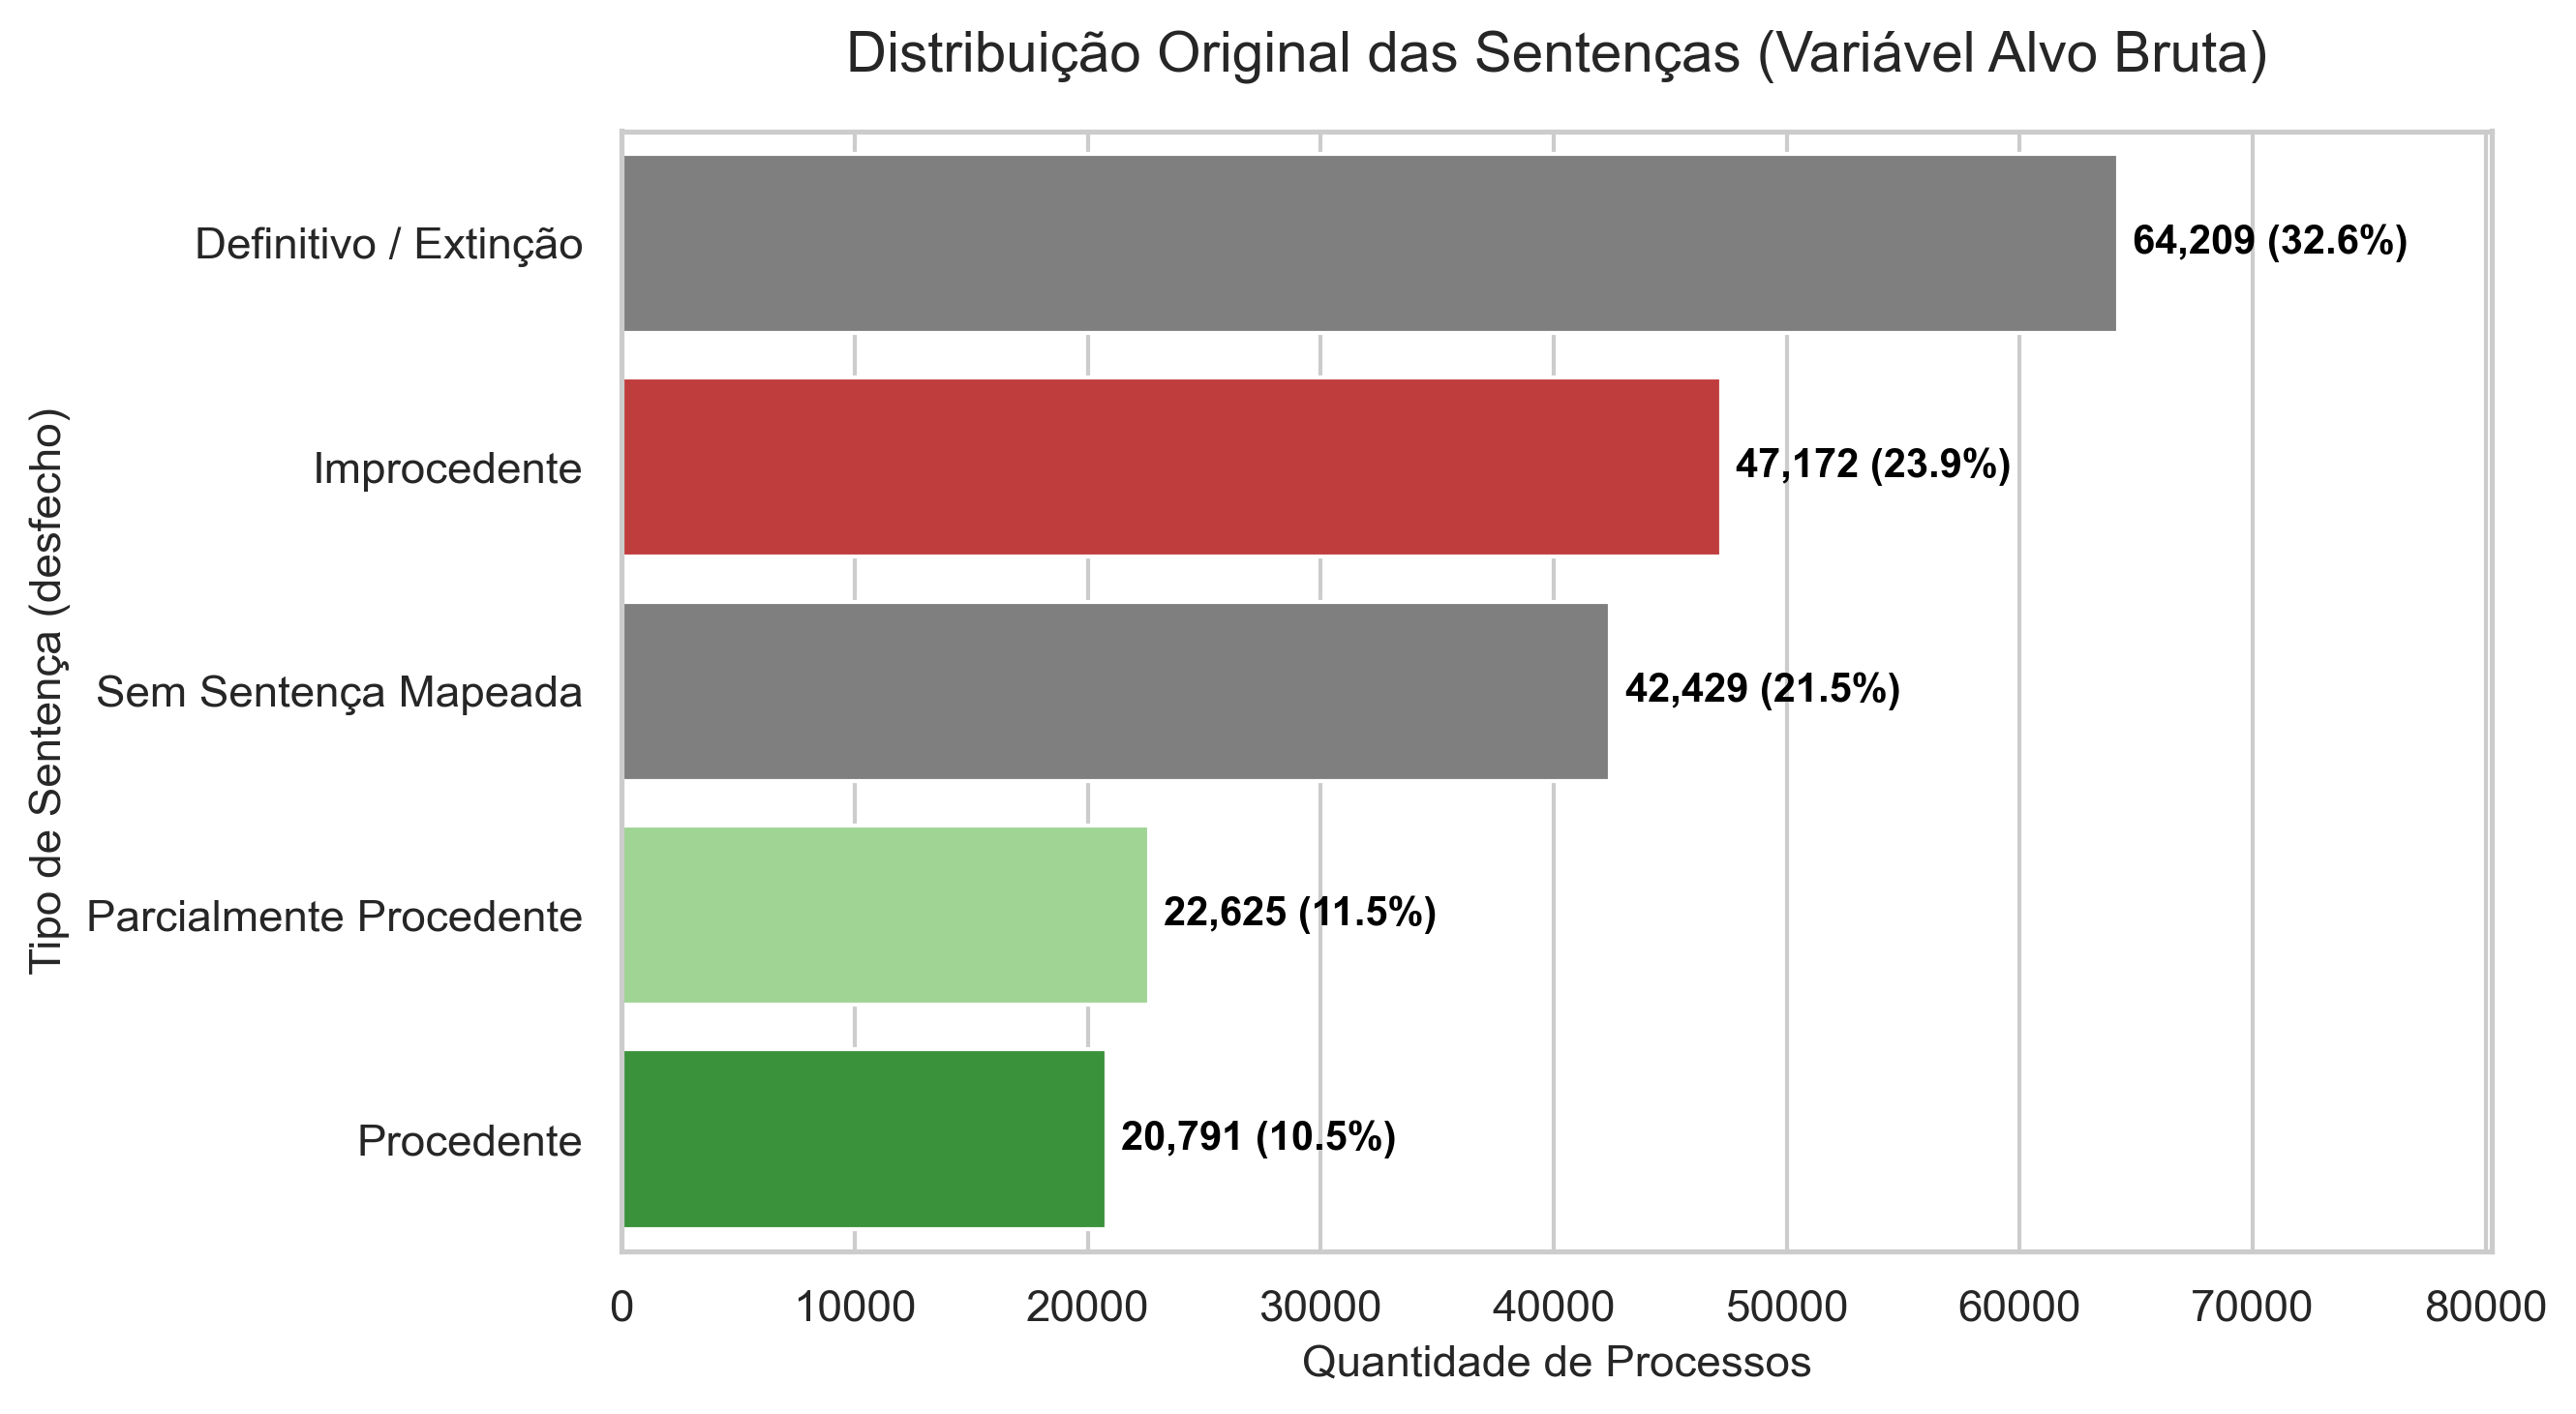

In [40]:
# --- Gráfico de Barras: Distribuição dos Desfechos Brutos ---
fig, ax = plt.subplots(figsize=(9, 5), dpi=300)

# Contagem dos desfechos na base higienizada (sem nulos de TPU)
desfechos_counts = df_higienizado['desfecho'].value_counts()

# Cores estratégicas para o TCC:
# Verde para vitórias, Vermelho para derrota, Cinza para descartados
colors = []
for idx in desfechos_counts.index:
    if 'Procedente' in str(idx) and 'Parcialmente' not in str(idx):
        colors.append('#2ca02c') # Verde
    elif 'Parcialmente' in str(idx):
        colors.append('#98df8a') # Verde claro
    elif 'Improcedente' in str(idx):
        colors.append('#d62728') # Vermelho
    else:
        colors.append('#7f7f7f') # Cinza (Descartados)

bars = sns.barplot(
    y=desfechos_counts.index, 
    x=desfechos_counts.values,
    palette=colors,
    ax=ax
)

# Anotações
for i, v in enumerate(desfechos_counts.values):
    pct = v / len(df_higienizado) * 100
    ax.text(v + (desfechos_counts.max() * 0.01), i, f'{v:,} ({pct:.1f}%)', 
            va='center', fontsize=10, color='black', fontweight='bold')

# Ajuste visual
max_val = desfechos_counts.max()
ax.set_xlim(0, max_val * 1.25)
ax.set_title('Distribuição Original das Sentenças (Variável Alvo Bruta)', fontsize=14, pad=15)
ax.set_xlabel('Quantidade de Processos', fontsize=11)
ax.set_ylabel('Tipo de Sentença (desfecho)', fontsize=11)

plt.tight_layout()
plt.show()


## 2. Filtragem de Desfechos de Mérito e Criação da Variável Alvo (`procedente_bin`)

Filtram-se exclusivamente as sentenças definitivas de mérito (`Procedente`, `Parcialmente Procedente` e `Improcedente`), descartando baixas administrativas sem julgamento de mérito.

Cria-se a variável alvo binária `procedente_bin`:
* `1` = Sentença Procedente ou Parcialmente Procedente (Vitória do Consumidor).
* `0` = Sentença Improcedente (Derrota do Consumidor).

In [41]:
merito_mask = df_higienizado['desfecho'].isin(['Procedente', 'Parcialmente Procedente', 'Improcedente'])
df_limpo = df_higienizado[merito_mask].copy()

df_limpo['procedente_bin'] = df_limpo['desfecho'].apply(
    lambda x: 1 if x in ['Procedente', 'Parcialmente Procedente'] else 0
)

print(f'Total de processos de mérito filtrados: {len(df_limpo):,}')
print('\nDistribuição da Variável Alvo (procedente_bin):')
print(df_limpo['procedente_bin'].value_counts(normalize=True).map('{:.2%}'.format))


Total de processos de mérito filtrados: 90,588

Distribuição da Variável Alvo (procedente_bin):
procedente_bin
0    52.07%
1    47.93%
Name: proportion, dtype: object


In [42]:
df_limpo.head()


,processo,vara,data_distribuicao,assunto_tpu,assunto_desc,desfecho,procedente_bin
0,80004222020208050001,4ª VARA DE RELACOES DE CONSUMO,20200102000000,6226,Inclusão Indevida em Cadastro de Inadimplentes,Procedente,1
2,80002204320208050001,17ª VARA DE RELACOES DE CONSUMO,20200102000000,6226,Inclusão Indevida em Cadastro de Inadimplentes,Improcedente,0
3,80002949720208050001,10ª VARA DE RELACOES DE CONSUMO,20200102000000,6226,Inclusão Indevida em Cadastro de Inadimplentes,Improcedente,0
4,80003130620208050001,16ª VARA DE RELACOES DE CONSUMO,20200102000000,6226,Inclusão Indevida em Cadastro de Inadimplentes,Improcedente,0
5,80001424920208050001,3ª VARA DE RELACOES DE CONSUMO,20200102000000,9607,Contratos Bancários,Improcedente,0


### 2.1 Diagnóstico Visual do Balanceamento de Classes (`procedente_bin`)

Visualizamos a distribuição de frequências absolutas e relativas da variável alvo binária para diagnosticar o balanço entre vitórias e derrotas do consumidor.

C:\Users\vinic\AppData\Local\Temp\ipykernel_27344\3050961763.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_temp, x='procedente_bin', palette=['#E74C3C', '#2ECC71'], edgecolor='black', linewidth=1.2)


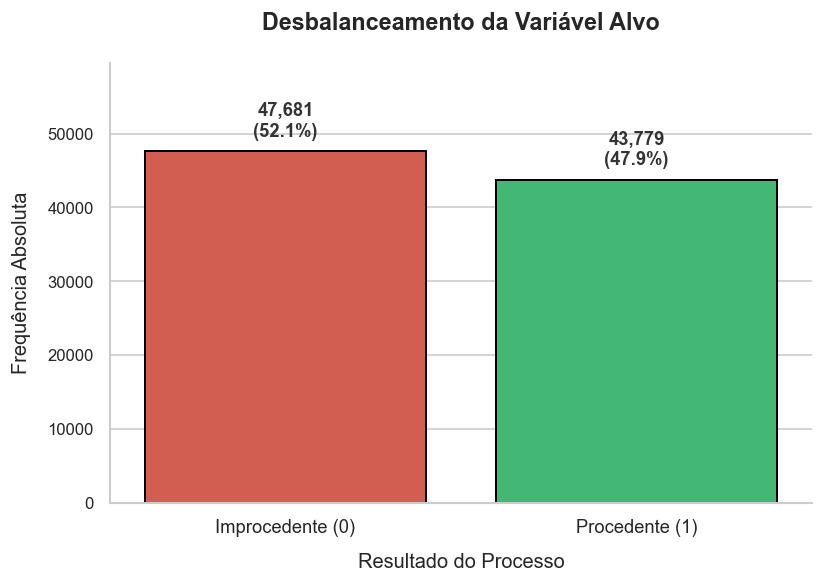

In [43]:
# Diagnóstico Visual: Gráfico de Barras Elegante
import matplotlib.pyplot as plt
import seaborn as sns

# Cria os dados temporários direto da base bruta para evitar erro de ordem de execução
df_temp = df_bruto[df_bruto['desfecho'].isin(['Procedente', 'Parcialmente Procedente', 'Improcedente'])].copy()
df_temp['procedente_bin'] = df_temp['desfecho'].apply(lambda x: 1 if x in ['Procedente', 'Parcialmente Procedente'] else 0)

plt.figure(figsize=(7, 5), dpi=120)
ax = sns.countplot(data=df_temp, x='procedente_bin', palette=['#E74C3C', '#2ECC71'], edgecolor='black', linewidth=1.2)

total = len(df_temp)
max_height = 0

# Adicionando os textos
for p in ax.patches:
    height = p.get_height()
    if height > max_height:
        max_height = height
        
    texto = f'{height:,.0f}\n({(height/total)*100:.1f}%)'
    ax.text(p.get_x() + p.get_width()/2., height + (max_height * 0.03),
            texto, ha='center', va='bottom', fontsize=11, fontweight='bold', color='#333333')

# A MÁGICA: Aumentar o teto do gráfico para o texto não bater no título
ax.set_ylim(0, max_height * 1.25)

plt.title('Desbalanceamento da Variável Alvo', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Resultado do Processo', fontsize=12, labelpad=10)
plt.ylabel('Frequência Absoluta', fontsize=12, labelpad=10)
plt.xticks([0, 1], ['Improcedente (0)', 'Procedente (1)'], fontsize=11)
plt.yticks(fontsize=10)

sns.despine()
plt.tight_layout()
plt.show()


### 2.2 Frequência Absoluta de Processos pelas 20 Varas de Consumo

Gráfico de barras horizontais ordenadas representando o volume total de processos distribuídos entre as 20 Varas de Relações de Consumo de Salvador (TJBA).

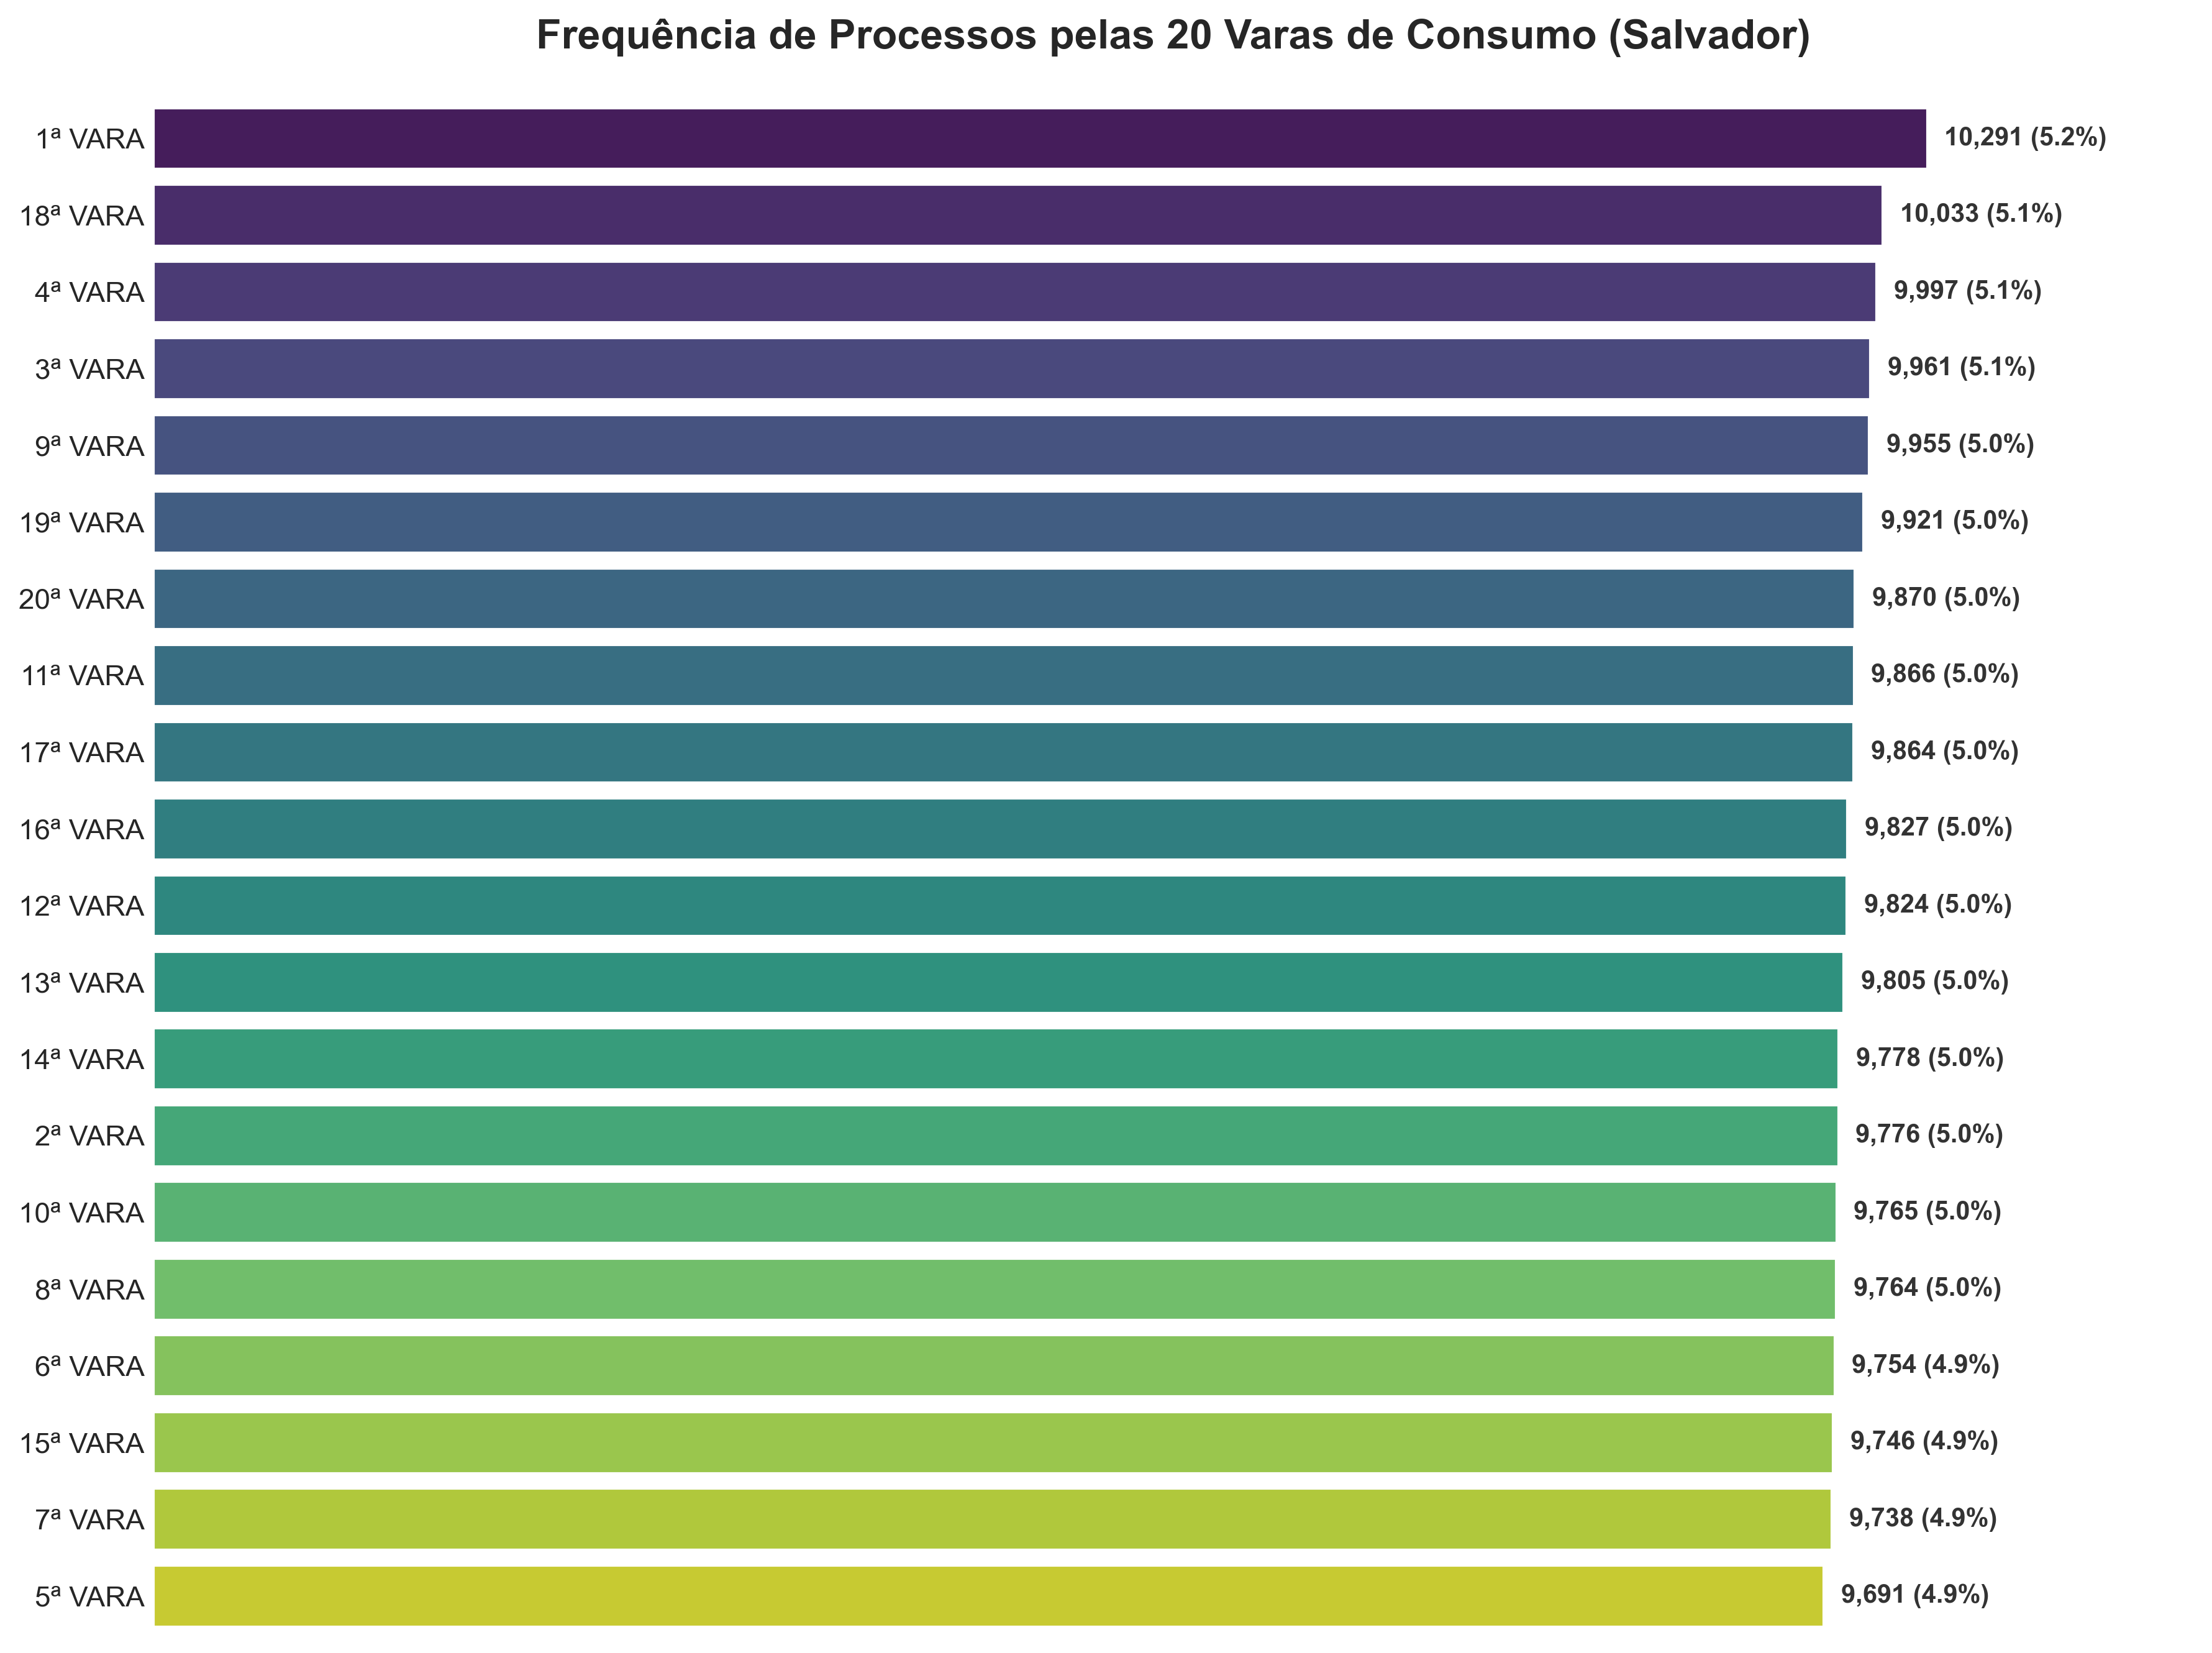

In [44]:
# --- Gráfico de Barras: Distribuição de Processos por Vara de Consumo ---
fig, ax = plt.subplots(figsize=(12, 9), dpi=300)

# Simplificando os nomes (removendo o texto repetitivo para ficar elegante)
varas_counts = df_higienizado['vara'].str.replace(' DE RELACOES DE CONSUMO', '', regex=False).value_counts()

sns.barplot(x=varas_counts.values, y=varas_counts.index, palette='viridis', ax=ax, hue=varas_counts.index, legend=False)

ax.set_title('Frequência de Processos pelas 20 Varas de Consumo (Salvador)', fontsize=16, fontweight='bold', pad=20)
ax.set_ylabel('') # Removendo label redundante do eixo Y
ax.set_xlabel('') # Removendo label do eixo X pois os números já estarão nas barras
ax.set_xlim(0, max(varas_counts.values) * 1.15)

# Removendo bordas e o eixo X (Tick labels) para um visual ultra-clean
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.xaxis.set_ticks([])
ax.tick_params(axis='y', length=0, labelsize=11)

# Anotando os valores direto nas barras
for p in ax.patches:
    width = p.get_width()
    if width > 0:
        pct = (width / len(df_higienizado)) * 100
        ax.annotate(f'{int(width):,} ({pct:.1f}%)', (width + 100, p.get_y() + p.get_height() / 2.),
                    ha='left', va='center', fontsize=10, fontweight='bold', color='#333333')

plt.tight_layout()
plt.show()


### 2.3 Frequência Absoluta dos Top 20 Assuntos TPU

Gráfico de barras horizontais exibindo os 20 temas mais frequentes da Tabela Processual Unificada (TPU) do CNJ no contencioso de consumo de Salvador.

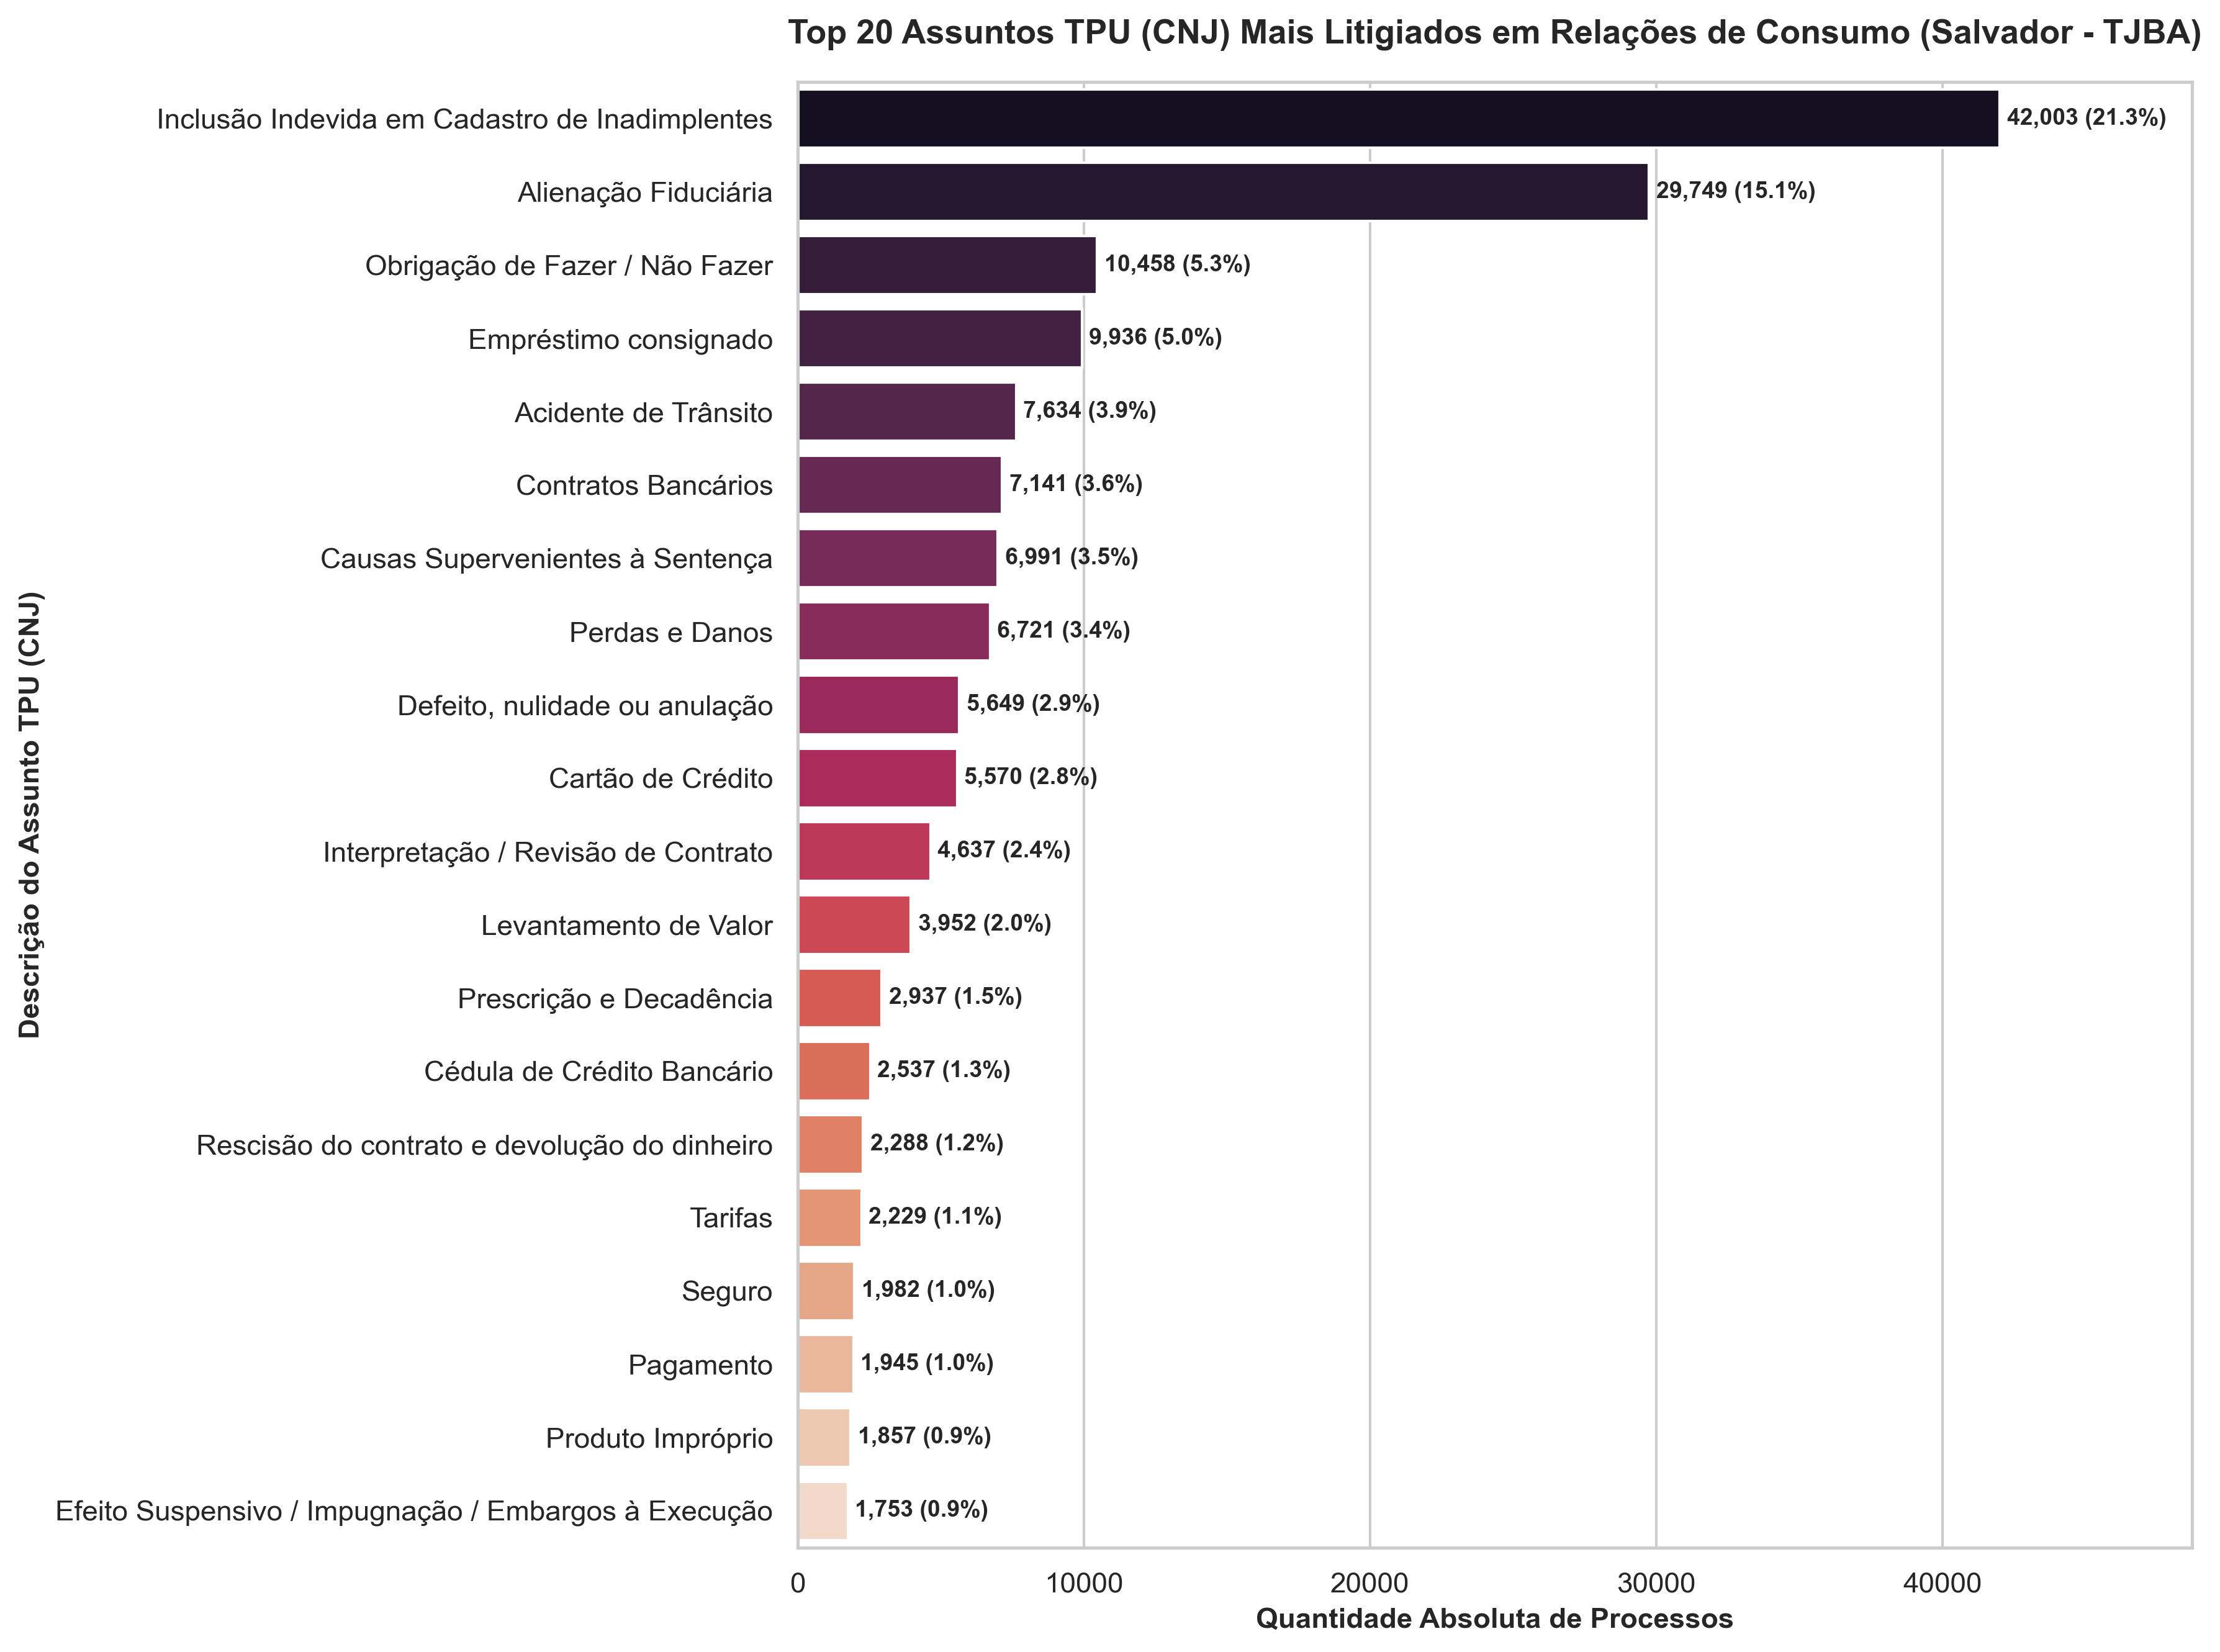

In [45]:
# --- Gráfico de Barras Horizontal: Top 20 Assuntos TPU ---
fig, ax = plt.subplots(figsize=(12, 9), dpi=300)
top20_tpu_counts = df_higienizado['assunto_desc'].value_counts().head(20)

sns.barplot(y=top20_tpu_counts.index, x=top20_tpu_counts.values, palette='rocket', ax=ax, hue=top20_tpu_counts.index, legend=False)
ax.set_title('Top 20 Assuntos TPU (CNJ) Mais Litigiados em Relações de Consumo (Salvador - TJBA)', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Quantidade Absoluta de Processos', fontsize=11, fontweight='bold')
ax.set_ylabel('Descrição do Assunto TPU (CNJ)', fontsize=11, fontweight='bold')
ax.set_xlim(0, max(top20_tpu_counts.values) * 1.16)

for p in ax.patches:
    width = p.get_width()
    if width > 0:
        pct = (width / len(df_higienizado)) * 100
        ax.annotate(f'{int(width):,} ({pct:.1f}%)', (width + 250, p.get_y() + p.get_height() / 2.),
                    ha='left', va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


## 3. Conversão da Data de Distribuição e Número do Processo (CNJ)

Convertemos o timestamp `data_distribuicao` (`AAAAMMDDHHMMSS`) para o tipo oficial `datetime` e realizamos a extração (*parse*) do ano de ajuizamento a partir do padrão NPU de 20 dígitos do CNJ (`NNNNNNN-DD.AAAA.J.TR.OOOO`).

In [46]:
df_limpo['dt_distribuicao'] = pd.to_datetime(
    df_limpo['data_distribuicao'].astype(str),
    format='%Y%m%d%H%M%S',
    errors='coerce'
)
df_limpo = df_limpo.dropna(subset=['dt_distribuicao']).sort_values('dt_distribuicao').reset_index(drop=True)

# Parse do Ano do CNJ (Dígitos 10 a 13)
proc_str = df_limpo['processo'].astype(str).str.zfill(20)
df_limpo['ano_cnj'] = proc_str.str[9:13].astype(int)

print('Distribuição de processos de mérito por ano de ajuizamento:')
print(df_limpo['dt_distribuicao'].dt.year.value_counts().sort_index())


Distribuição de processos de mérito por ano de ajuizamento:
dt_distribuicao
2020    14290
2021    18936
2022    22072
2023    22401
2024    12886
Name: count, dtype: int64


In [47]:
print("Colunas: ", df_limpo.columns.tolist())
print("Quantidade de colunas: ", len(df_limpo.columns))
display(df_limpo.head())


Colunas:  ['processo', 'vara', 'data_distribuicao', 'assunto_tpu', 'assunto_desc', 'desfecho', 'procedente_bin', 'dt_distribuicao', 'ano_cnj']
Quantidade de colunas:  9


,processo,vara,data_distribuicao,assunto_tpu,assunto_desc,desfecho,procedente_bin,dt_distribuicao,ano_cnj
0,80004222020208050001,4ª VARA DE RELACOES DE CONSUMO,20200102000000,6226,Inclusão Indevida em Cadastro de Inadimplentes,Procedente,1,2020-01-02,2020
1,80003511820208050001,7ª VARA DE RELACOES DE CONSUMO,20200102000000,6226,Inclusão Indevida em Cadastro de Inadimplentes,Improcedente,0,2020-01-02,2020
2,80002637720208050001,17ª VARA DE RELACOES DE CONSUMO,20200102000000,6226,Inclusão Indevida em Cadastro de Inadimplentes,Improcedente,0,2020-01-02,2020
3,80003754620208050001,14ª VARA DE RELACOES DE CONSUMO,20200102000000,6226,Inclusão Indevida em Cadastro de Inadimplentes,Improcedente,0,2020-01-02,2020
4,80002212820208050001,7ª VARA DE RELACOES DE CONSUMO,20200102000000,6226,Inclusão Indevida em Cadastro de Inadimplentes,Improcedente,0,2020-01-02,2020


## 4. Engenharia de Atributos Específicos de Domínio Jurídico

Extraímos marcadores temporais institucionais e operacionais do Judiciário:

* **`is_recesso_forense`**: Indica o período de Recesso Forense e Suspensão de Prazos (Art. 220 do CPC — 20 de Dezembro a 20 de Janeiro).
* **`trimestre`**: Quadrimestre/Trimestre do ano (captura o encerramento das metas de produtividade do CNJ no 4º trimestre).
* **`is_fim_ano`** / **`is_inicio_ano`**: Indicadores institucionais de encerramento e retomada do exercício forense.
* **`mes_num`**, **`dia_num`**, **`dia_semana_num`**: Atributos ordinais discretos otimizados para cortes de hiperplanos ortogonais em Árvores de decisão.

In [48]:
month = df_limpo['dt_distribuicao'].dt.month
day = df_limpo['dt_distribuicao'].dt.day
dw = df_limpo['dt_distribuicao'].dt.dayofweek

df_limpo['mes_num'] = month
df_limpo['dia_num'] = day
df_limpo['dia_semana_num'] = dw
df_limpo['trimestre'] = df_limpo['dt_distribuicao'].dt.quarter

# Flags Institucionais do Processo Civil (Recesso de 20/Dez a 20/Jan)
df_limpo['is_recesso_forense'] = (((month == 12) & (day >= 20)) | ((month == 1) & (day <= 20))).astype(int)
df_limpo['is_fim_ano'] = (month == 12).astype(int)
df_limpo['is_inicio_ano'] = (month == 1).astype(int)
# A coluna ano_distribuicao foi removida do modelo.

df_limpo[['dt_distribuicao', 'mes_num', 'trimestre', 'is_recesso_forense', 'is_fim_ano']].head()


,dt_distribuicao,mes_num,trimestre,is_recesso_forense,is_fim_ano
0,2020-01-02,1,1,1,0
1,2020-01-02,1,1,1,0
2,2020-01-02,1,1,1,0
3,2020-01-02,1,1,1,0
4,2020-01-02,1,1,1,0


In [49]:
print("Colunas: ", df_limpo.columns.tolist())
print("Quantidade de colunas: ", len(df_limpo.columns))
display(df_limpo.head(3))


Colunas:  ['processo', 'vara', 'data_distribuicao', 'assunto_tpu', 'assunto_desc', 'desfecho', 'procedente_bin', 'dt_distribuicao', 'ano_cnj', 'mes_num', 'dia_num', 'dia_semana_num', 'trimestre', 'is_recesso_forense', 'is_fim_ano', 'is_inicio_ano']
Quantidade de colunas:  16


,processo,vara,data_distribuicao,assunto_tpu,assunto_desc,desfecho,procedente_bin,dt_distribuicao,ano_cnj,mes_num,dia_num,dia_semana_num,trimestre,is_recesso_forense,is_fim_ano,is_inicio_ano
0,80004222020208050001,4ª VARA DE RELACOES DE CONSUMO,20200102000000,6226,Inclusão Indevida em Cadastro de Inadimplentes,Procedente,1,2020-01-02,2020,1,2,3,1,1,0,1
1,80003511820208050001,7ª VARA DE RELACOES DE CONSUMO,20200102000000,6226,Inclusão Indevida em Cadastro de Inadimplentes,Improcedente,0,2020-01-02,2020,1,2,3,1,1,0,1
2,80002637720208050001,17ª VARA DE RELACOES DE CONSUMO,20200102000000,6226,Inclusão Indevida em Cadastro de Inadimplentes,Improcedente,0,2020-01-02,2020,1,2,3,1,1,0,1


### 4.1 Visualização da Frequência do Recesso Forense (`is_recesso_forense`)

Gráfico de barras representando o volume absoluto de processos ajuizados durante o período de Recesso/Plantão Forense comparado aos dias normais.

C:\Users\vinic\AppData\Local\Temp\ipykernel_27344\2715792666.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Não (0)', 'Sim (1)'], fontsize=11)


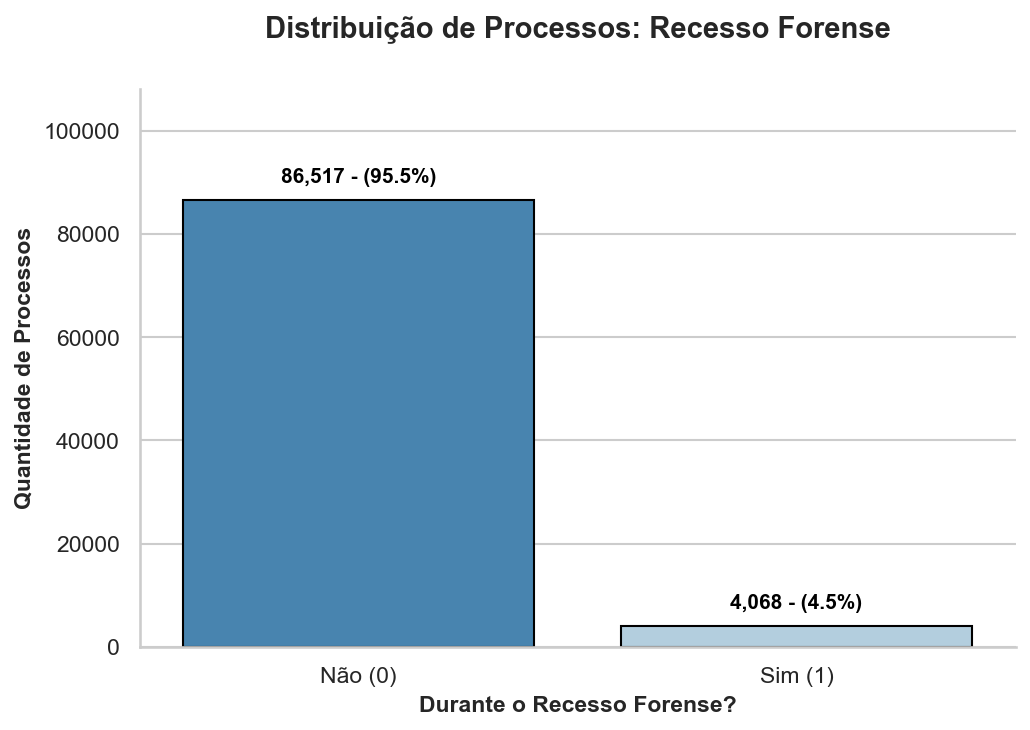

In [50]:
# Visualização da Frequência do Recesso Forense
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(7, 5), dpi=150)
df_temp = df_limpo['is_recesso_forense'].value_counts().reset_index()
df_temp.columns = ['is_recesso_forense', 'count']

sns.barplot(data=df_temp, x='is_recesso_forense', y='count', palette='Blues_r', edgecolor='black', ax=ax, hue='is_recesso_forense', legend=False)

max_y = df_temp['count'].max()
ax.set_ylim(0, max_y * 1.25)

ax.set_title('Distribuição de Processos: Recesso Forense', fontsize=14, fontweight='bold', pad=25)
ax.set_ylabel('Quantidade de Processos', fontsize=11, fontweight='bold')
ax.set_xlabel('Durante o Recesso Forense?', fontsize=11, fontweight='bold')
ax.set_xticklabels(['Não (0)', 'Sim (1)'], fontsize=11)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        pct = (height / len(df_limpo)) * 100
        # AQUI ESTAVA O ERRO DE SINTAXE (nova linha escapada corretamente)
        texto = f'{int(height):,} - ({pct:.1f}%)'
        ax.annotate(texto, (p.get_x() + p.get_width() / 2., height + (max_y * 0.03)), ha='center', va='bottom', fontsize=10, fontweight='bold', color='black')

sns.despine()
plt.tight_layout()
plt.show()


## 5. Divisão Temporal Rígida (Treino: 2020–2023 | Teste Out-of-Time: 2024)

Realizamos a divisão cronológica dos dados para reproduzir fielmente o cenário real de predição jurídica: treinamento com a série histórica passada (2020 a 2023: 78.568 processos) e teste cego no futuro (2024: 12.889 processos).

> **Nota Metodológica contra Vazamento de Dados (*Data Leakage*):**
> A divisão temporal é realizada rigorosamente nesta etapa — **antes** de qualquer cálculo de codificação categórica (*Target Encoding* e *One-Hot Encoding*). Qualquer parâmetro de transformação estatística é aprendido exclusivamente sobre a partição de treinamento e aplicado (*transform*) no conjunto de teste, garantindo a integridade científica do experimento.


In [51]:
from sklearn.model_selection import KFold, TimeSeriesSplit
import pandas as pd

# 1. DIVISÃO TEMPORAL (Sem Leakage)
mask_train = df_limpo['dt_distribuicao'].dt.year < 2024
mask_test = df_limpo['dt_distribuicao'].dt.year == 2024

df_train = df_limpo[mask_train].copy().reset_index(drop=True)
df_test = df_limpo[mask_test].copy().reset_index(drop=True)

print(f'Treino (2020-2023): {len(df_train):,} processos')
print(f'Teste  (2024):      {len(df_test):,} processos')


Treino (2020-2023): 77,699 processos
Teste  (2024):      12,886 processos


## 6. Codificação de Variáveis e Matriz Final de Covariáveis

### 6.1 Target Encoding Out-Of-Fold ($K=5$) com Suavização Bayesiana ($m=20$)

Mapeamos as variáveis categóricas de alta cardinalidade (`vara` e `assunto_tpu`) para a taxa histórica de procedência suavizada (*Empirical Bayes Shrinkage*):

$$ \text{Target\_Encoded}_i = \frac{n_i \cdot \mu_i + m \cdot \mu_{\text{global}}}{n_i + m} $$

Para **evitar Vazamento de Dados (*Data Leakage*)**, a codificação no conjunto de treino é realizada estritamente via *Out-of-Fold* (OOF). Dessa forma, a taxa de procedência atribuída a cada processo é calculada a partir dos demais dados, sem que o desfecho do próprio registro interfira na sua média.

> **Fundamentação no Livro AME:** Conforme recomendado por Rafael Izbicki e Tiago Mendonça dos Santos em *Aprendizado de Máquina: Uma Abordagem Estatística* (2020), a codificação de variáveis categóricas de alta cardinalidade utilizando o próprio alvo (*Target Encoding*) introduz risco severo de sobreajuste (*overfitting*) se calculada globalmente. A abordagem *Out-of-Fold* é a técnica rigorosa preconizada na literatura para assegurar estimativas não enviesadas.


In [52]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import KFold

class BayesianTargetEncoder(BaseEstimator, TransformerMixin):
    """
    Scikit-learn compatible custom Transformer for Bayesian Target Encoding with OOF.
    Prevents Data Leakage using internal K-Fold Out-Of-Fold encoding.
    (Conforme recomendacao do livro AME - Aprendizado de Maquina: uma abordagem estatistica)
    """
    def __init__(self, cols, m=20.0, n_splits=5):
        self.cols = cols
        self.m = m
        self.n_splits = n_splits
        self.mapping_ = {}
        self.global_mean_ = 0.0

    def fit(self, X, y):
        self.global_mean_ = np.mean(y)
        temp_df = X.copy()
        temp_df['target_temp_col'] = np.array(y)
        for col in self.cols:
            stats = temp_df.groupby(col)['target_temp_col'].agg(['count', 'mean'])
            smooth = (stats['count'] * stats['mean'] + self.m * self.global_mean_) / (stats['count'] + self.m)
            self.mapping_[col] = smooth
        return self

    def transform(self, X, y=None):
        X_encoded = X.copy()
        if y is not None:
            # Training time: Out-of-Fold encoding using KFold
            temp_df = X.copy()
            temp_df['target_temp_col'] = np.array(y)
            kf = KFold(n_splits=self.n_splits, shuffle=True, random_state=42)
            
            for col in self.cols:
                oof_encoded = pd.Series(np.nan, index=X.index, dtype=float)
                
                for train_idx, val_idx in kf.split(X):
                    train_fold = temp_df.iloc[train_idx]
                    val_fold = temp_df.iloc[val_idx]
                    fold_global_mean = train_fold['target_temp_col'].mean()
                    stats = train_fold.groupby(col)['target_temp_col'].agg(['count', 'mean'])
                    smooth = (stats['count'] * stats['mean'] + self.m * fold_global_mean) / (stats['count'] + self.m)
                    oof_encoded.iloc[val_idx] = val_fold[col].map(smooth).fillna(fold_global_mean)
                
                new_col_name = 'vara_encoded' if col == 'vara' else 'tpu_encoded' if col == 'assunto_tpu' else col + '_encoded'
                col_idx = X_encoded.columns.get_loc(col)
                X_encoded.insert(col_idx, new_col_name, oof_encoded)
                X_encoded.drop(columns=[col], inplace=True)
        else:
            # Test time: Use the mapping fitted on the whole training set
            for col in self.cols:
                encoded_col = X_encoded[col].map(self.mapping_[col]).fillna(self.global_mean_)
                new_col_name = 'vara_encoded' if col == 'vara' else 'tpu_encoded' if col == 'assunto_tpu' else col + '_encoded'
                col_idx = X_encoded.columns.get_loc(col)
                X_encoded.insert(col_idx, new_col_name, encoded_col)
                X_encoded.drop(columns=[col], inplace=True)
        return X_encoded

    def fit_transform(self, X, y=None, **fit_params):
        return self.fit(X, y).transform(X, y)

### 6.2 One-Hot Encoding e Prevenção de Viés Temporal ('Miopia' das Árvores para o Futuro)

Nesta etapa, consolidamos as covariáveis finais da matriz de aprendizagem:
1. **One-Hot Encoding nos Top 15 Assuntos TPU:** Cria variáveis binárias isoladas para os temas mais litigiosos.
2. **One-Hot Encoding nas Variáveis Cíclicas:** Transforma atributos sazonais ordinais (`mes_num`, `dia_semana_num`, `trimestre`) em categorias binarizadas, garantindo paridade de representação para modelos lineares e não-lineares.

**Por que removemos a variável Ano Absoluto (`ano_cnj`)?**
Modelos baseados em árvores de decisão (Random Forest, XGBoost) particionam o espaço por hiperplanos ortogonais e não extrapolam tendências numéricas além do domínio observado no treino. Ao treinar com os anos de 2020 a 2023, um modelo de árvore memorizaria esses valores numéricos e, ao receber o ano de 2024 no teste cego, alocaria os novos processos na mesma folha terminal de 2023, gerando viés e memorização espúria (*Overfitting*). A substituição do ano contínuo por marcadores sazonais (meses, trimestres, recesso forense) garante que o modelo aprenda padrões cíclicos perenes e generalizáveis.


In [53]:
# --- Preparacao Final das Covariaveis (Feature Engineering) ---
# 1. Aplicando One-Hot Encoding apenas para os Top 15 Assuntos TPU
top_15_tpu = df_train['assunto_tpu'].value_counts().head(15).index
tpu_cols = []
for tpu in top_15_tpu:
    cname = f'tpu_{tpu}'
    tpu_cols.append(cname)
    df_train[cname] = (df_train['assunto_tpu'] == tpu).astype(int)
    df_test[cname] = (df_test['assunto_tpu'] == tpu).astype(int)

# 1.5 Aplicando One-Hot Encoding para variaveis ordinais/ciclicas
time_cols = ['mes_num', 'dia_num', 'dia_semana_num', 'trimestre']
ohe_time_cols = []
for c in time_cols:
    unique_vals = sorted(df_train[c].unique())
    for val in unique_vals:
        new_col = f'{c}_{val}'
        ohe_time_cols.append(new_col)
        df_train[new_col] = (df_train[c] == val).astype(int)
        df_test[new_col] = (df_test[c] == val).astype(int)

# 2. Consolidando todas as variaveis avancadas
cols_baseline = ['vara', 'assunto_tpu']
cols_avancadas = [
    'vara', 'assunto_tpu',
    'is_recesso_forense', 'is_inicio_ano', 'is_fim_ano'
] + tpu_cols + ohe_time_cols

X_train = df_train[cols_avancadas]
y_train = df_train['procedente_bin']

X_test = df_test[cols_avancadas]
y_test = df_test['procedente_bin']

print(f'\n[+] Total de covariaveis utilizadas pelo modelo: {len(cols_avancadas)}')
print('[+] Lista de covariaveis:')
for i, col in enumerate(cols_avancadas, 1):
    print(f' {i}. {col}')

print('\n[+] Amostra final da matriz de treinamento (X_train):')
display(X_train.head())


[+] Total de covariaveis utilizadas pelo modelo: 74
[+] Lista de covariaveis:
 1. vara
 2. assunto_tpu
 3. is_recesso_forense
 4. is_inicio_ano
 5. is_fim_ano
 6. tpu_6226
 7. tpu_9517
 8. tpu_10671
 9. tpu_11806
 10. tpu_7698
 11. tpu_10435
 12. tpu_9160
 13. tpu_9582
 14. tpu_7772
 15. tpu_9607
 16. tpu_5632
 17. tpu_4703
 18. tpu_7770
 19. tpu_7703
 20. tpu_11860
 21. mes_num_1
 22. mes_num_2
 23. mes_num_3
 24. mes_num_4
 25. mes_num_5
 26. mes_num_6
 27. mes_num_7
 28. mes_num_8
 29. mes_num_9
 30. mes_num_10
 31. mes_num_11
 32. mes_num_12
 33. dia_num_1
 34. dia_num_2
 35. dia_num_3
 36. dia_num_4
 37. dia_num_5
 38. dia_num_6
 39. dia_num_7
 40. dia_num_8
 41. dia_num_9
 42. dia_num_10
 43. dia_num_11
 44. dia_num_12
 45. dia_num_13
 46. dia_num_14
 47. dia_num_15
 48. dia_num_16
 49. dia_num_17
 50. dia_num_18
 51. dia_num_19
 52. dia_num_20
 53. dia_num_21
 54. dia_num_22
 55. dia_num_23
 56. dia_num_24
 57. dia_num_25
 58. dia_num_26
 59. dia_num_27
 60. dia_num_28
 61. dia

,vara,assunto_tpu,is_recesso_forense,is_inicio_ano,is_fim_ano,tpu_6226,tpu_9517,tpu_10671,tpu_11806,tpu_7698,...,dia_semana_num_1,dia_semana_num_2,dia_semana_num_3,dia_semana_num_4,dia_semana_num_5,dia_semana_num_6,trimestre_1,trimestre_2,trimestre_3,trimestre_4
0,4ª VARA DE RELACOES DE CONSUMO,6226,1,1,0,1,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0
1,7ª VARA DE RELACOES DE CONSUMO,6226,1,1,0,1,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0
2,17ª VARA DE RELACOES DE CONSUMO,6226,1,1,0,1,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0
3,14ª VARA DE RELACOES DE CONSUMO,6226,1,1,0,1,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0
4,7ª VARA DE RELACOES DE CONSUMO,6226,1,1,0,1,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0


## 7. Modelagem e Treinamento

Nesta seção, consolidaremos o treinamento dos 3 modelos: Regressão Logística (Baseline), Random Forest e XGBoost.

### 7.1 Regressão Logística (Baseline Interpretável)

A **Regressão Logística** atua como o modelo fundamental (*Baseline*) deste estudo. No contexto jurídico, algoritmos de "caixa-branca" são extremamente valorizados por sua transparência total e explicabilidade (*Explainable AI*). Segundo a literatura estatística, a adoção de modelos complexos e não-paramétricos só se justifica se houver um ganho preditivo estatisticamente substancial. Caso contrário, pelo Princípio da Navalha de Ockham, o modelo mais simples deve prevalecer, permitindo ao operador do Direito entender o peso exato de cada variável na decisão.

In [54]:
import numpy as np
from sklearn.model_selection import TimeSeriesSplit
tscv = TimeSeriesSplit(n_splits=4)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd
import time

print('--- INICIANDO TREINAMENTO COM GRID SEARCH: REGRESSÃO LOGÍSTICA ---')
t0 = time.time()

pipeline_base = Pipeline([
    ('target_encoder', BayesianTargetEncoder(cols=['vara', 'assunto_tpu'], m=20.0)),
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(random_state=42, class_weight='balanced', solver='saga', max_iter=2000))
])

param_grid_lr = [
    {
        'clf__penalty': ['l1', 'l2'],
        'clf__C': [0.01, 0.1, 1.0, 10.0]
    },
    {
        'clf__penalty': ['elasticnet'],
        'clf__C': [0.01, 0.1, 1.0, 10.0],
        'clf__l1_ratio': [0.2, 0.5, 0.8]
    }
]

grid_lr = GridSearchCV(
    estimator=pipeline_base,
    param_grid=param_grid_lr,
    scoring='roc_auc',
    cv=tscv,
    n_jobs=2,
    verbose=1
)

X_treino_atual = df_train[cols_avancadas]
y_treino_atual = y_train
grid_lr.fit(X_treino_atual, y_treino_atual)

pipeline_lr = grid_lr.best_estimator_

t_treino = time.time() - t0
print('')
print(f'[+] Treinamento e Validacao Cruzada concluidos em {t_treino:.1f} segundos!')
print(f'[+] Melhores hiperparametros escolhidos: {grid_lr.best_params_}')
print(f'[+] Melhor ROC-AUC na Validacao Cruzada (Treino): {grid_lr.best_score_:.4f}')
print('')

# 4. Avaliar no Teste de 2024
X_teste_atual = df_test[cols_avancadas]
y_proba = pipeline_lr.predict_proba(X_teste_atual)[:, 1]

# Predicao In-Sample apenas para vizualizacao rapida (threshold final eh out-of-fold na celula 45)
proba_train_lr = pipeline_lr.predict_proba(X_treino_atual)[:, 1]
from sklearn.metrics import precision_recall_curve
precisions, recalls, thresholds = precision_recall_curve(y_treino_atual, proba_train_lr)
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-9)
best_idx = np.argmax(f1_scores)
th_lr = thresholds[best_idx]
print(f"Optimal threshold for LR (In-Sample): {th_lr}")
y_pred = (y_proba >= th_lr).astype(int)

# Salvar predicoes
probs = {'Regressão Logística': y_proba}
preds = {'Regressão Logística': y_pred}

--- INICIANDO TREINAMENTO COM GRID SEARCH: REGRESSÃO LOGÍSTICA ---
Fitting 4 folds for each of 20 candidates, totalling 80 fits

[+] Treinamento e Validacao Cruzada concluidos em 80.7 segundos!
[+] Melhores hiperparametros escolhidos: {'clf__C': 0.01, 'clf__l1_ratio': 0.8, 'clf__penalty': 'elasticnet'}
[+] Melhor ROC-AUC na Validacao Cruzada (Treino): 0.7761

Optimal threshold for LR (In-Sample): 0.401197431116873


### 7.2 Random Forest (Ensemble Bagging)

A **Random Forest** é um algoritmo de *Ensemble* que cria múltiplas Árvores de decisão e combina seus resultados. Cada árvore tenta "fatiar" os processos judiciais buscando minimizar a impureza (utilizando o Índice de Gini, onde a incerteza é máxima em 0.5 e mínima nas folhas puras). 

**Atenção ao Desbalanceamento:** Para evitar a armadilha de modelos que focam apenas na acurácia geral (classificando a grande maioria na classe majoritária, um erro comum alertado na literatura), configuramos a floresta com pesos balanceados (`class_weight='balanced_subsample'`), forçando o algoritmo a dar a devida atenção aos desfechos menos frequentes.

In [55]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
import time
import numpy as np
from sklearn.metrics import precision_recall_curve

print('--- INICIANDO TREINAMENTO COM GRID SEARCH: RANDOM FOREST ---')
t0 = time.time()

pipeline_rf = Pipeline([
    ('target_encoder', BayesianTargetEncoder(cols=['vara', 'assunto_tpu'], m=20.0)),
    ('clf', RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1))
])

param_grid_rf = {
    'clf__n_estimators': [100, 200, 300],
    'clf__max_depth': [5, 10, 15],
    'clf__min_samples_split': [2, 5, 10]
}

grid_rf = GridSearchCV(
    estimator=pipeline_rf,
    param_grid=param_grid_rf,
    scoring='roc_auc',
    cv=tscv,
    n_jobs=2,
    verbose=1
)

grid_rf.fit(X_treino_atual, y_treino_atual)
rf_best = grid_rf.best_estimator_

t_treino = time.time() - t0
print('')
print(f'[+] Treinamento e Validacao Cruzada concluidos em {t_treino:.1f} segundos!')
print(f'[+] Melhores hiperparametros escolhidos: {grid_rf.best_params_}')
print(f'[+] Melhor ROC-AUC na Validacao Cruzada (Treino): {grid_rf.best_score_:.4f}')

# Teste
y_proba_rf = rf_best.predict_proba(X_teste_atual)[:, 1]
probs['Random Forest'] = y_proba_rf

proba_train_rf = rf_best.predict_proba(X_treino_atual)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_treino_atual, proba_train_rf)
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-9)
th_rf = thresholds[np.argmax(f1_scores)]
print(f"Optimal threshold for RF (In-Sample): {th_rf}")

preds['Random Forest'] = (y_proba_rf >= th_rf).astype(int)

--- INICIANDO TREINAMENTO COM GRID SEARCH: RANDOM FOREST ---
Fitting 4 folds for each of 27 candidates, totalling 108 fits

[+] Treinamento e Validacao Cruzada concluidos em 107.5 segundos!
[+] Melhores hiperparametros escolhidos: {'clf__max_depth': 15, 'clf__min_samples_split': 10, 'clf__n_estimators': 300}
[+] Melhor ROC-AUC na Validacao Cruzada (Treino): 0.7745
Optimal threshold for RF (In-Sample): 0.41576056577699644


### 7.3 XGBoost (Ensemble Boosting)

O **XGBoost** representa o estado da arte em modelagem para dados tabulares. Diferente da Random Forest (que constrói árvores independentes em paralelo), o XGBoost constrói árvores de forma sequencial, onde cada nova árvore foca em corrigir os erros residuais da anterior. 

Devido à sua alta flexibilidade matemática, ele tem uma tendência ao *Overfitting* (memorizar ruídos dos dados de treino em vez de aprender padrões generalizáveis). Para mitigar isso, utilizamos a Validação Cruzada Temporal (`TimeSeriesSplit`) dentro de um `GridSearchCV`, limitando a profundidade máxima das árvores (`max_depth`).

In [56]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
import time
import numpy as np
from sklearn.metrics import precision_recall_curve

print('--- INICIANDO TREINAMENTO COM GRID SEARCH: XGBOOST ---')
t0 = time.time()

pipeline_xgb = Pipeline([
    ('target_encoder', BayesianTargetEncoder(cols=['vara', 'assunto_tpu'], m=20.0)),
    ('clf', XGBClassifier(random_state=42, eval_metric='logloss', scale_pos_weight=y_treino_atual.value_counts()[0]/y_treino_atual.value_counts()[1], n_jobs=-1))
])

param_grid_xgb = {
    'clf__n_estimators': [100, 200, 300],
    'clf__max_depth': [3, 5, 7],
    'clf__learning_rate': [0.01, 0.1, 0.2]
}

grid_xgb = GridSearchCV(
    estimator=pipeline_xgb,
    param_grid=param_grid_xgb,
    scoring='roc_auc',
    cv=tscv,
    n_jobs=2,
    verbose=1
)

grid_xgb.fit(X_treino_atual, y_treino_atual)
xgb_best = grid_xgb.best_estimator_

t_treino = time.time() - t0
print('')
print(f'[+] Treinamento e Validacao Cruzada concluidos em {t_treino:.1f} segundos!')
print(f'[+] Melhores hiperparametros escolhidos: {grid_xgb.best_params_}')
print(f'[+] Melhor ROC-AUC na Validacao Cruzada (Treino): {grid_xgb.best_score_:.4f}')

# Teste
y_proba_xgb = xgb_best.predict_proba(X_teste_atual)[:, 1]
probs['XGBoost'] = y_proba_xgb

proba_train_xgb = xgb_best.predict_proba(X_treino_atual)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_treino_atual, proba_train_xgb)
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-9)
th_xgb = thresholds[np.argmax(f1_scores)]
print(f"Optimal threshold for XGBoost (In-Sample): {th_xgb}")

preds['XGBoost'] = (y_proba_xgb >= th_xgb).astype(int)

--- INICIANDO TREINAMENTO COM GRID SEARCH: XGBOOST ---
Fitting 4 folds for each of 27 candidates, totalling 108 fits

[+] Treinamento e Validacao Cruzada concluidos em 57.8 segundos!
[+] Melhores hiperparametros escolhidos: {'clf__learning_rate': 0.01, 'clf__max_depth': 5, 'clf__n_estimators': 100}
[+] Melhor ROC-AUC na Validacao Cruzada (Treino): 0.7769
Optimal threshold for XGBoost (In-Sample): 0.46494540572166443


### 7.4 Predições Consolidadas (Treino e Teste)

In [57]:
# Predicoes de Treino (Out-Of-Fold manual via TimeSeriesSplit para evitar overfitting)
import numpy as np
from sklearn.base import clone
from sklearn.metrics import precision_recall_curve

probs_treino = {'Regressão Logística': np.zeros(len(y_treino_atual)), 
                'Random Forest': np.zeros(len(y_treino_atual)), 
                'XGBoost': np.zeros(len(y_treino_atual))}
preds_treino = {}

# Faremos um loop manual iterando nos folds. A 1a dobra sera preenchida com NaN para evitar vazamento in-sample
first_train_idx = next(tscv.split(X_treino_atual))[0]

for model_name, model_obj in [('Regressão Logística', pipeline_lr), ('Random Forest', rf_best), ('XGBoost', xgb_best)]:
    oof_probs = np.zeros(len(y_treino_atual))
    oof_probs[first_train_idx] = np.nan
    
    for train_idx, val_idx in tscv.split(X_treino_atual):
        m_clone = clone(model_obj)
        m_clone.fit(X_treino_atual.iloc[train_idx], y_treino_atual.iloc[train_idx])
        oof_probs[val_idx] = m_clone.predict_proba(X_treino_atual.iloc[val_idx])[:, 1]
        
    probs_treino[model_name] = oof_probs

def get_optimal_threshold(y_true, y_proba):
    valid_idx = ~np.isnan(y_proba)
    precisions, recalls, thresholds = precision_recall_curve(y_true.values[valid_idx], y_proba[valid_idx])
    f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-9)
    return thresholds[np.argmax(f1_scores)]

th_lr = get_optimal_threshold(y_treino_atual, probs_treino['Regressão Logística'])
th_rf = get_optimal_threshold(y_treino_atual, probs_treino['Random Forest'])
th_xgb = get_optimal_threshold(y_treino_atual, probs_treino['XGBoost'])

preds_treino['Regressão Logística'] = (probs_treino['Regressão Logística'] >= th_lr).astype(int)
preds_treino['Random Forest'] = (probs_treino['Random Forest'] >= th_rf).astype(int)
preds_treino['XGBoost'] = (probs_treino['XGBoost'] >= th_xgb).astype(int)

# Predicoes de Teste c/ Threshold OOF
probs = {}
preds = {}

# Logistica
probs['Regressão Logística'] = pipeline_lr.predict_proba(X_teste_atual)[:, 1]
preds['Regressão Logística'] = (probs['Regressão Logística'] >= th_lr).astype(int)

# Random Forest
probs['Random Forest'] = rf_best.predict_proba(X_teste_atual)[:, 1]
preds['Random Forest'] = (probs['Random Forest'] >= th_rf).astype(int)

# XGBoost
probs['XGBoost'] = xgb_best.predict_proba(X_teste_atual)[:, 1]
preds['XGBoost'] = (probs['XGBoost'] >= th_xgb).astype(int)

print(f"Thresholds Otimos (Out-Of-Fold Reais): LR={th_lr:.3f}, RF={th_rf:.3f}, XGB={th_xgb:.3f}")

Thresholds Otimos (Out-Of-Fold Reais): LR=0.392, RF=0.428, XGB=0.471


## 8. Avaliação Consolidada (Treino vs. Teste com Intervalo de Confiança)

Muitos estudos em Machine Learning cometem o erro metodológico de comparar modelos baseando-se apenas na *Estimativa Pontual* (o número exato da métrica), declarando um vencedor por diferenças decimais. 

Para garantir rigor científico, implementamos uma função de **Bootstrapping** (reamostragem) para calcular o **Intervalo de Confiança a 95%** do erro preditivo no conjunto *Out-of-Time* de 2024. Se os intervalos dos modelos baseados em árvores (Random Forest/XGBoost) se sobrepuserem ao intervalo da Regressão Logística, conclui-se um **empate estatístico**, fortalecendo a escolha do modelo mais simples e interpretável.

In [58]:

import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Função de Intervalo de Confiança via Bootstrapping
def calcular_ic_metric(y_true, y_pred, metric_func, n_bootstraps=1000, alpha=0.05):
    rng = np.random.RandomState(42)
    bootstrapped_scores = []
    
    y_true_arr = np.array(y_true)
    y_pred_arr = np.array(y_pred)
    
    for i in range(n_bootstraps):
        indices = rng.randint(0, len(y_pred_arr), len(y_pred_arr))
        if len(np.unique(y_true_arr[indices])) < 2:
            continue
        score = metric_func(y_true_arr[indices], y_pred_arr[indices])
        bootstrapped_scores.append(score)
        
    sorted_scores = np.array(bootstrapped_scores)
    sorted_scores.sort()
    
    lower_bound = sorted_scores[int((alpha/2) * len(sorted_scores))]
    upper_bound = sorted_scores[int((1 - alpha/2) * len(sorted_scores))]
    return lower_bound, upper_bound

# Relatório Consolidado
for nome in probs.keys():
    print(f'\n================ {nome.upper()} ================')
    
    y_p_treino = preds_treino[nome]
    y_pr_treino = probs_treino[nome]
    print('--- PERFORMANCE NO TREINO (2020-2023) ---')
    valid_idx = ~np.isnan(y_pr_treino)
    y_t_valid = y_treino_atual[valid_idx]
    y_p_valid = y_p_treino[valid_idx]
    y_pr_valid = y_pr_treino[valid_idx]
    print(f'Acurácia: {accuracy_score(y_t_valid, y_p_valid):.4f}')
    print(f'ROC-AUC:  {roc_auc_score(y_t_valid, y_pr_valid):.4f}')
    
    y_p = preds[nome]
    y_pr = probs[nome]
    print('\n--- PERFORMANCE NO TESTE OUT-OF-TIME (2024) ---')
    
    acc = accuracy_score(y_test, y_p)
    ic_acc_l, ic_acc_u = calcular_ic_metric(y_test, y_p, accuracy_score)
    print(f'Acurácia: {acc:.4f}  [IC 95%: {ic_acc_l:.4f} - {ic_acc_u:.4f}]')

    prec = precision_score(y_test, y_p)
    ic_prec_l, ic_prec_u = calcular_ic_metric(y_test, y_p, precision_score)
    print(f'Precisão: {prec:.4f}  [IC 95%: {ic_prec_l:.4f} - {ic_prec_u:.4f}]')

    rec = recall_score(y_test, y_p)
    ic_rec_l, ic_rec_u = calcular_ic_metric(y_test, y_p, recall_score)
    print(f'Recall:   {rec:.4f}  [IC 95%: {ic_rec_l:.4f} - {ic_rec_u:.4f}]')

    f1 = f1_score(y_test, y_p)
    ic_f1_l, ic_f1_u = calcular_ic_metric(y_test, y_p, f1_score)
    print(f'F1-Score: {f1:.4f}  [IC 95%: {ic_f1_l:.4f} - {ic_f1_u:.4f}]')

    auc = roc_auc_score(y_test, y_pr)
    ic_auc_l, ic_auc_u = calcular_ic_metric(y_test, y_pr, roc_auc_score)
    print(f'ROC-AUC:  {auc:.4f}  [IC 95%: {ic_auc_l:.4f} - {ic_auc_u:.4f}]')



================ REGRESSÃO LOGÍSTICA ================
--- PERFORMANCE NO TREINO (2020-2023) ---
Acurácia: 0.6810
ROC-AUC:  0.7761

--- PERFORMANCE NO TESTE OUT-OF-TIME (2024) ---
Acurácia: 0.6762  [IC 95%: 0.6678 - 0.6846]
Precisão: 0.6787  [IC 95%: 0.6695 - 0.6880]
Recall:   0.8757  [IC 95%: 0.8678 - 0.8829]
F1-Score: 0.7647  [IC 95%: 0.7578 - 0.7720]
ROC-AUC:  0.7313  [IC 95%: 0.7226 - 0.7403]

================ RANDOM FOREST ================
--- PERFORMANCE NO TREINO (2020-2023) ---
Acurácia: 0.6955
ROC-AUC:  0.7744

--- PERFORMANCE NO TESTE OUT-OF-TIME (2024) ---
Acurácia: 0.6825  [IC 95%: 0.6747 - 0.6904]
Precisão: 0.6907  [IC 95%: 0.6813 - 0.7000]
Recall:   0.8542  [IC 95%: 0.8461 - 0.8623]
F1-Score: 0.7638  [IC 95%: 0.7570 - 0.7709]
ROC-AUC:  0.7313  [IC 95%: 0.7225 - 0.7404]

================ XGBOOST ================
--- PERFORMANCE NO TREINO (2020-2023) ---
Acurácia: 0.7058
ROC-AUC:  0.7764

--- PERFORMANCE NO TESTE OUT-OF-TIME (2024) ---
Acurácia: 0.6887  [IC 95%: 0.6811 - 0.

### 8.1 Relatórios de Classificação (*Classification Report*)

Detalhamento das métricas estatísticas (Precisão, Recall e F1-Score) calculadas isoladamente para cada classe.

In [59]:

from sklearn.metrics import classification_report

print("="*50)
print("RELATÓRIOS DE CLASSIFICAÇÃO (TESTE 2024)")
print("="*50 + "\n")

target_names = ['Improcedente (0)', 'Procedente (1)']

for nome, y_p in preds.items():
    print(f'>>> Modelo: {nome}')
    print(classification_report(y_test, y_p, target_names=target_names))
    print("-" * 50)


RELATÓRIOS DE CLASSIFICAÇÃO (TESTE 2024)

>>> Modelo: Regressão Logística
                  precision    recall  f1-score   support

Improcedente (0)       0.67      0.38      0.48      5141
  Procedente (1)       0.68      0.88      0.76      7745

        accuracy                           0.68     12886
       macro avg       0.67      0.63      0.62     12886
    weighted avg       0.67      0.68      0.65     12886

--------------------------------------------------
>>> Modelo: Random Forest
                  precision    recall  f1-score   support

Improcedente (0)       0.66      0.42      0.52      5141
  Procedente (1)       0.69      0.85      0.76      7745

        accuracy                           0.68     12886
       macro avg       0.67      0.64      0.64     12886
    weighted avg       0.68      0.68      0.66     12886

--------------------------------------------------
>>> Modelo: XGBoost
                  precision    recall  f1-score   support

Improcedente (0) 

## 9. Curvas ROC Comparativas

A **Curva ROC** e a métrica **AUC** (Área Sob a Curva) avaliam a capacidade do modelo de separar processos procedentes de improcedentes, independentemente do ponto de corte (*threshold*). Quanto mais próxima a curva estiver do canto superior esquerdo (AUC = 1.0), melhor o modelo. A linha tracejada diagonal representa um classificador aleatório (AUC = 0.5).

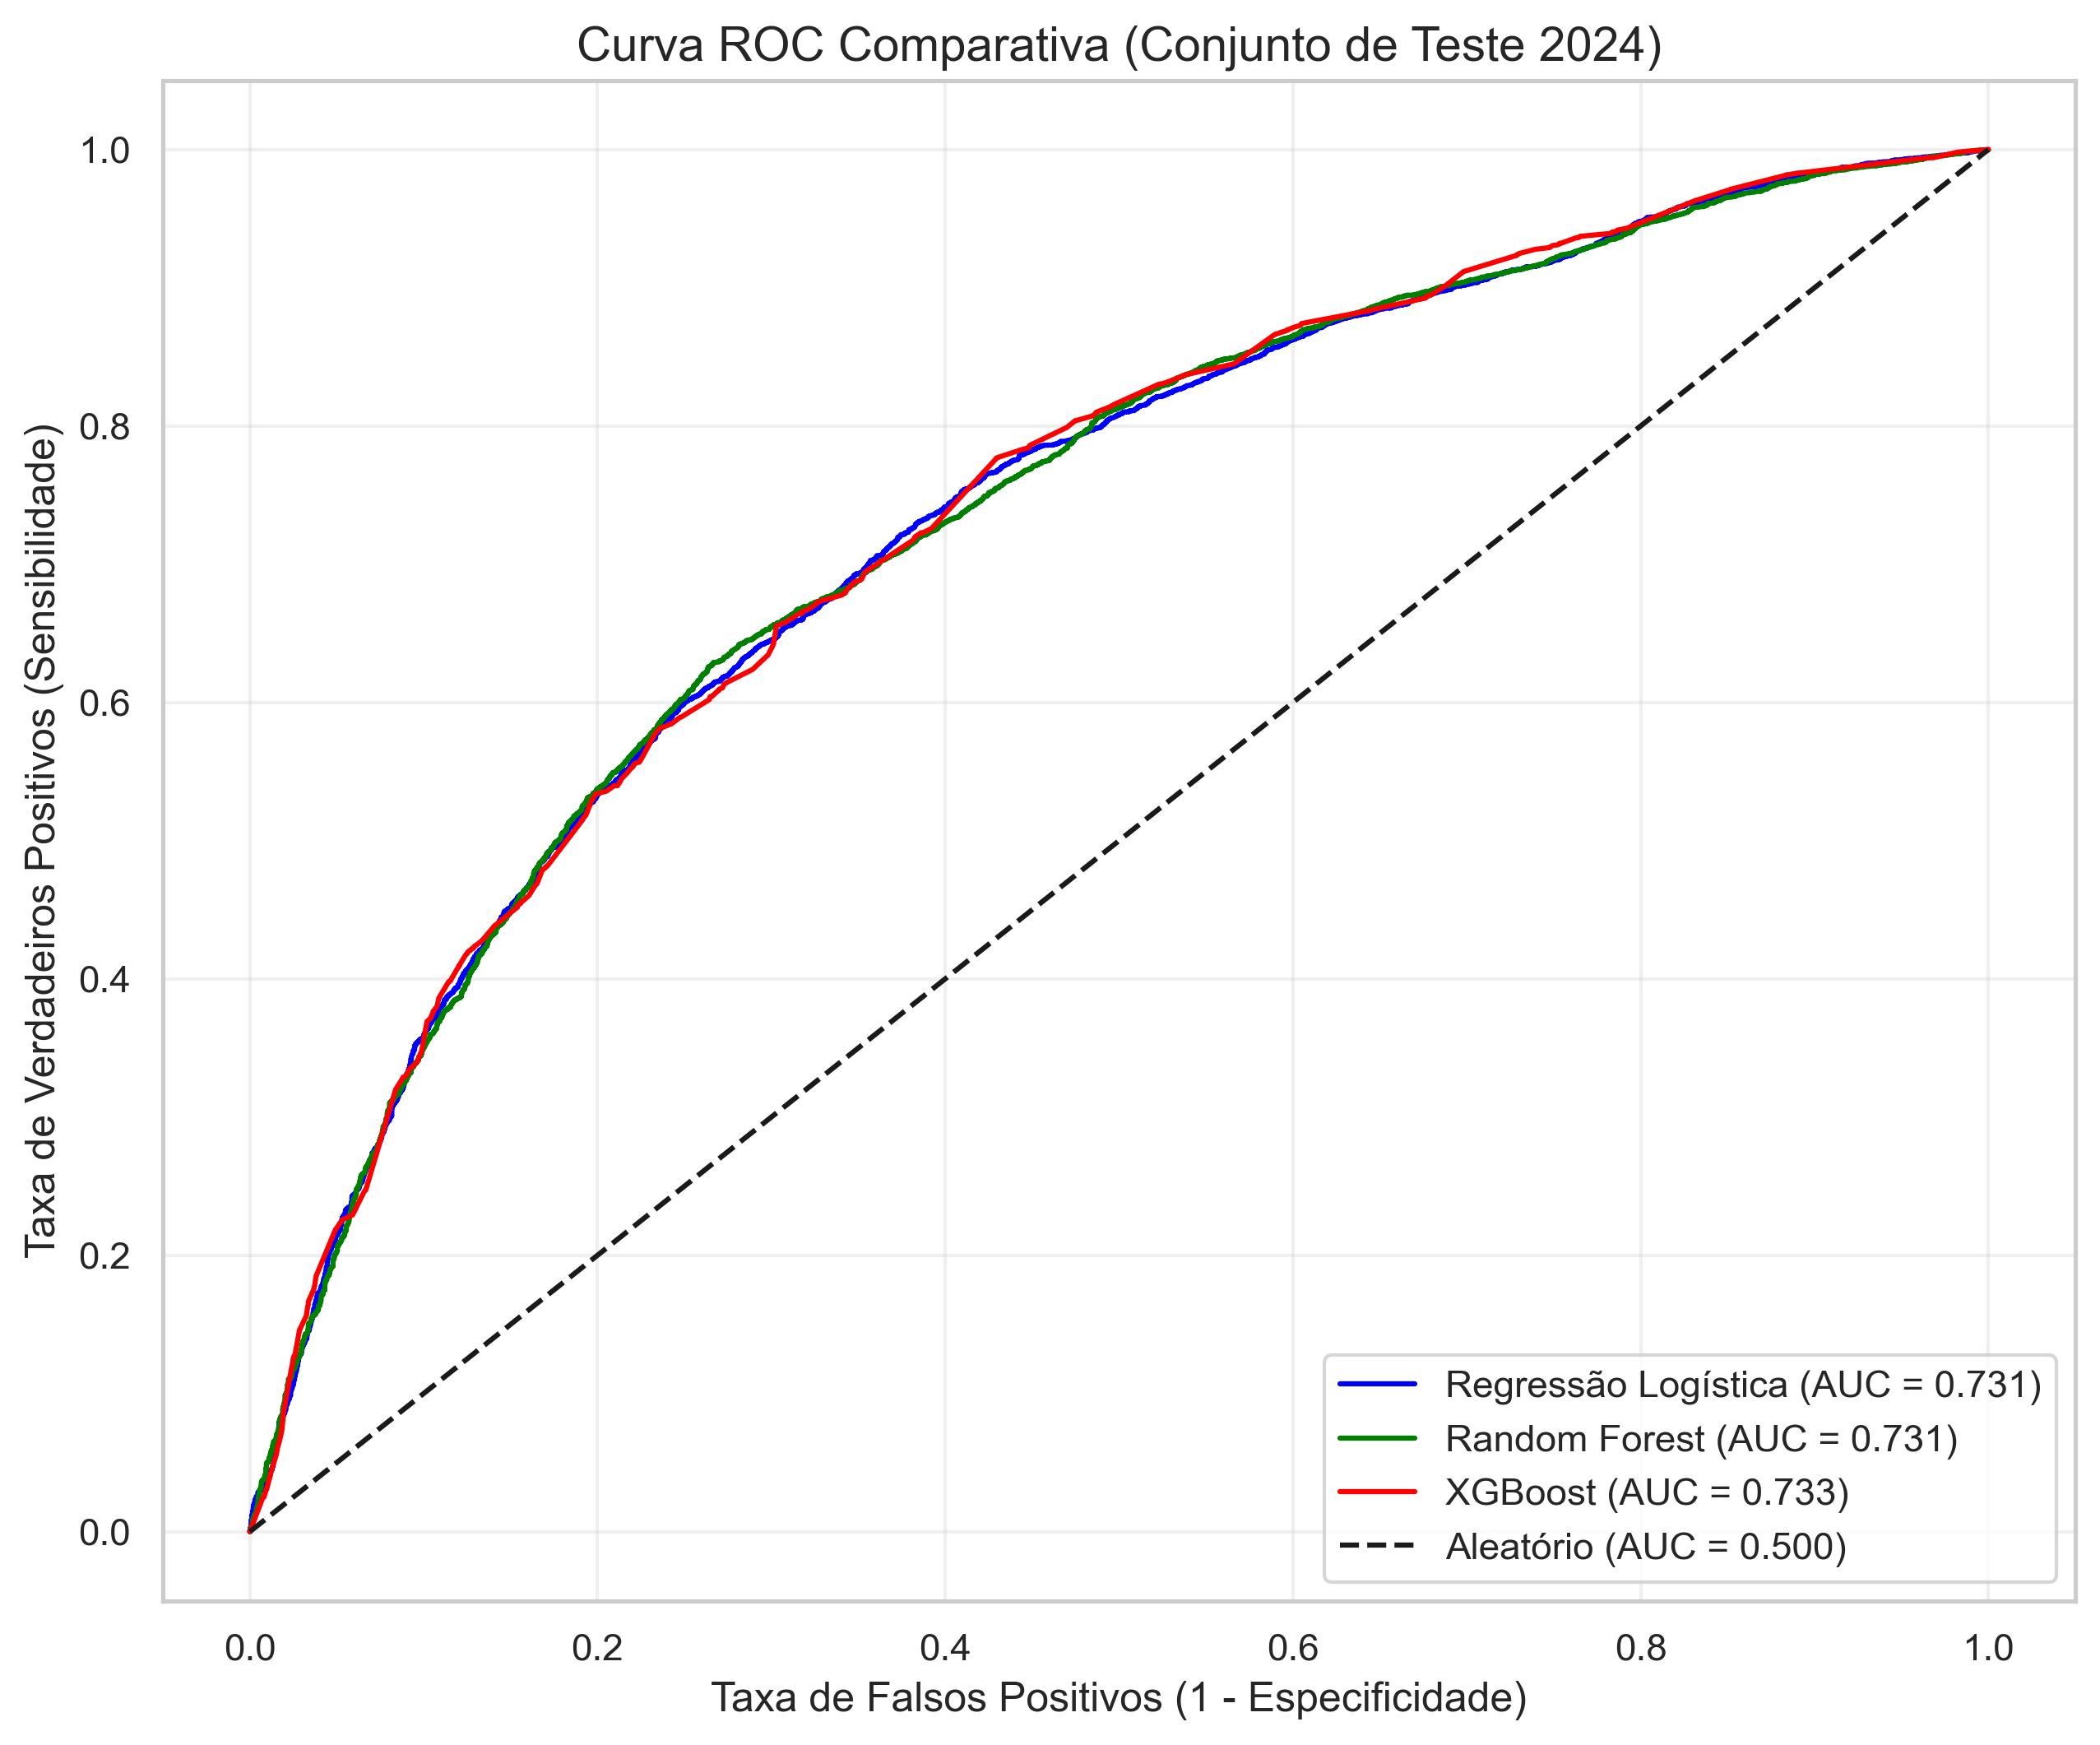

In [60]:

from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8), dpi=300)

cores = {'Regressão Logística': 'blue', 'Random Forest': 'green', 'XGBoost': 'red'}

for nome, y_pr in probs.items():
    fpr, tpr, _ = roc_curve(y_test, y_pr)
    auc_val = roc_auc_score(y_test, y_pr)
    plt.plot(fpr, tpr, label=f'{nome} (AUC = {auc_val:.3f})', color=cores[nome])

plt.plot([0, 1], [0, 1], 'k--', label='Aleatório (AUC = 0.500)')
plt.title('Curva ROC Comparativa (Conjunto de Teste 2024)', fontsize=14)
plt.xlabel('Taxa de Falsos Positivos (1 - Especificidade)', fontsize=12)
plt.ylabel('Taxa de Verdadeiros Positivos (Sensibilidade)', fontsize=12)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, alpha=0.3)
plt.savefig('resultados/curva_roc_3_modelos.png', bbox_inches='tight', dpi=300)
plt.show()


### 9.1 Curvas Precision-Recall Comparativas 

A Curva *Precision-Recall* é uma métrica fundamental no Direito, especialmente para o advogado do autor. Ela explicita o *trade-off* entre conseguir identificar todas as vitórias possíveis (Recall) e evitar dar falsos alarmes de causas ganhas ao cliente (Precisão).

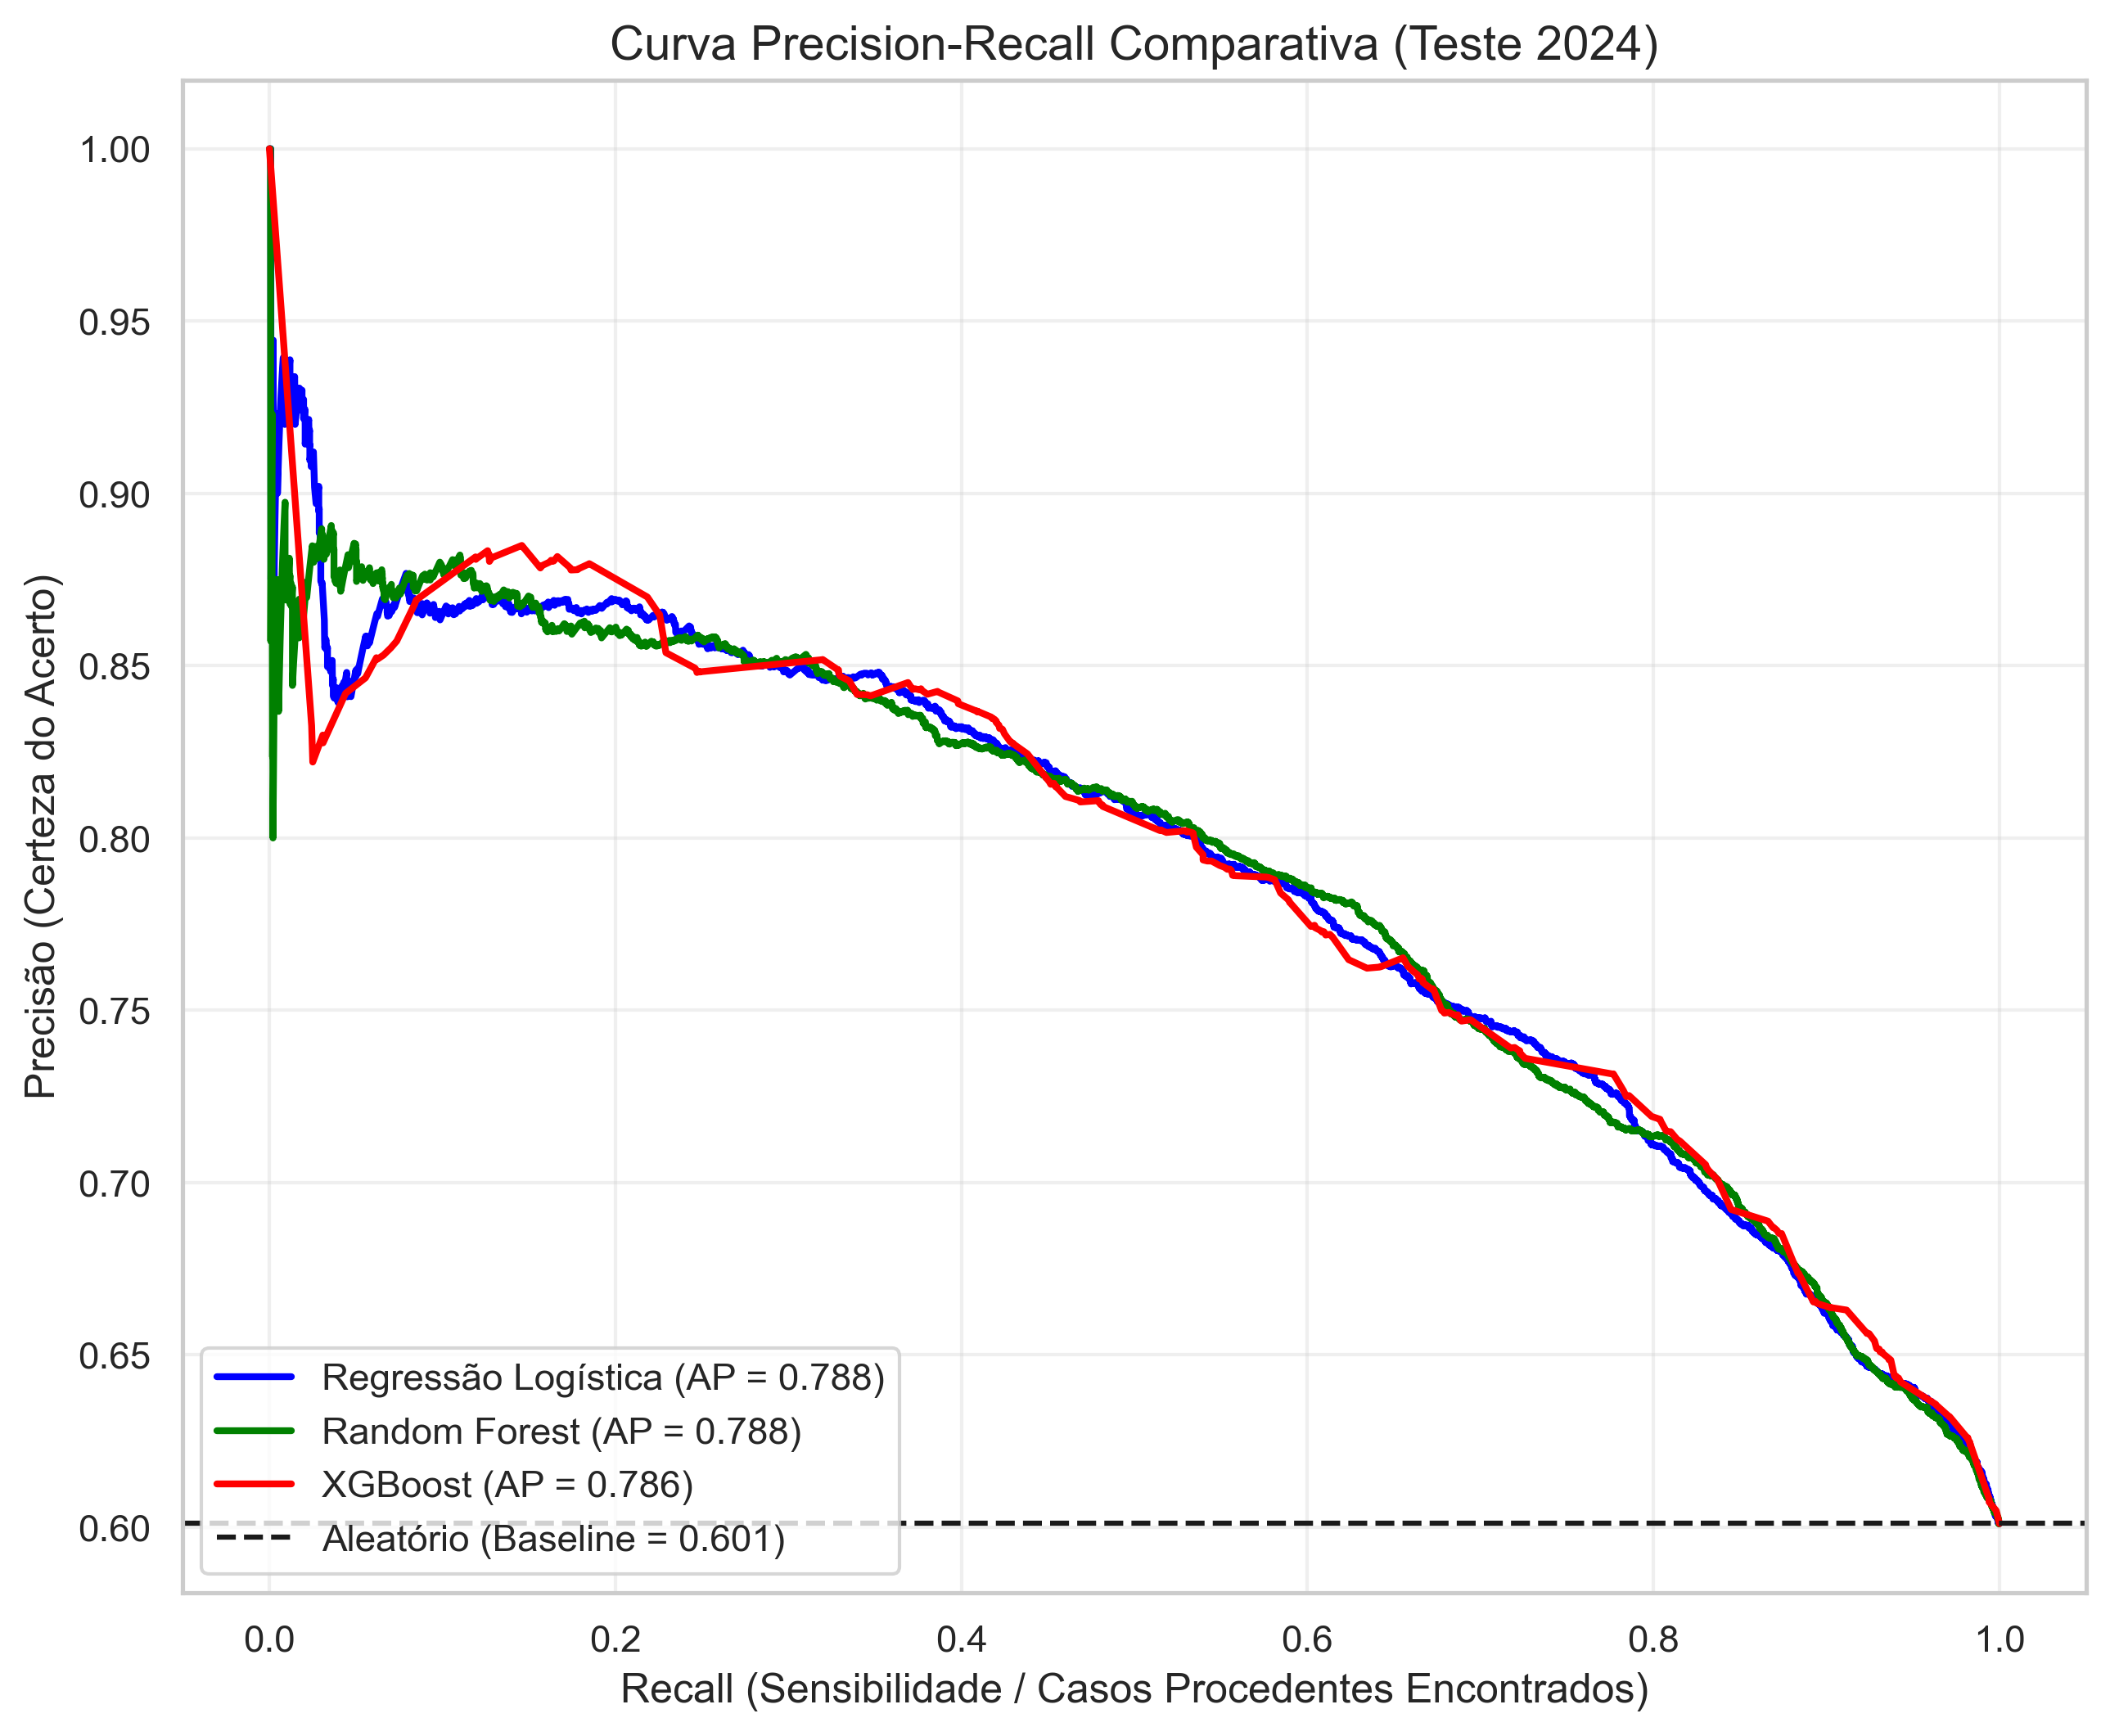

In [61]:

from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8), dpi=300)

for nome, y_pr in probs.items():
    precision, recall, _ = precision_recall_curve(y_test, y_pr)
    ap_val = average_precision_score(y_test, y_pr)
    plt.plot(recall, precision, label=f'{nome} (AP = {ap_val:.3f})', color=cores[nome], linewidth=2)

# Linha de baseline (Proporção real de casos procedentes no teste)
baseline = sum(y_test) / len(y_test)
plt.axhline(y=baseline, color='k', linestyle='--', label=f'Aleatório (Baseline = {baseline:.3f})')

plt.title('Curva Precision-Recall Comparativa (Teste 2024)', fontsize=14)
plt.xlabel('Recall (Sensibilidade / Casos Procedentes Encontrados)', fontsize=12)
plt.ylabel('Precisão (Certeza do Acerto)', fontsize=12)
plt.legend(loc='lower left', fontsize=11)
plt.grid(True, alpha=0.3)
plt.savefig('resultados/curva_pr_3_modelos.png', bbox_inches='tight', dpi=300)
plt.show()


## 10. Matrizes de Confusão

A Matriz de Confusão é vital na Jurimetria devido à assimetria de custos dos erros. Para um banco, o custo de um Falso Positivo (prever ganho para o consumidor, não propor acordo e acabar condenado) é financeiramente muito diferente do custo de um Falso Negativo (prever derrota, e fazer um acordo desnecessário). Analisar a distribuição dos erros de cada modelo ajuda a alinhar o uso da IA à estratégia do departamento jurídico.

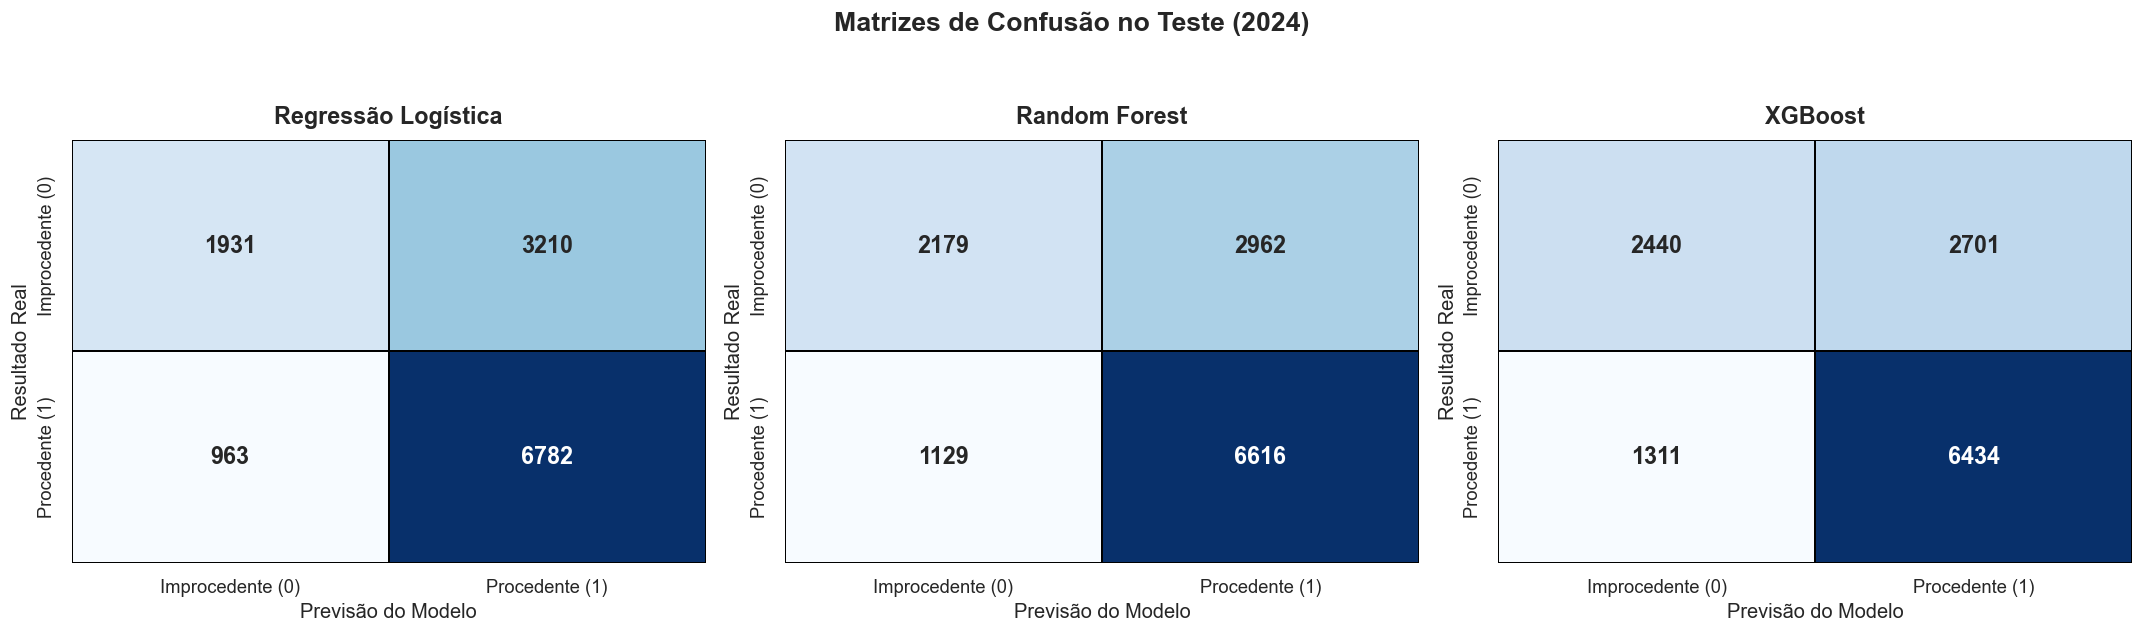

In [62]:
# ==========================================
# 10. MATRIZES DE CONFUSÃO COMPARATIVAS
# ==========================================
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# O dicionário 'preds' contém as previsões dos três modelos!
fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=120)
fig.suptitle('Matrizes de Confusão no Teste (2024)', fontsize=16, fontweight='bold', y=1.05)

# Acessando as chaves diretamente do dicionário 'preds'
for idx, nome in enumerate(preds.keys()):
    cm = confusion_matrix(y_test, preds[nome])
    
    # Usando seaborn heatmap para ficar com uma estética de monografia impecável
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[idx],
                annot_kws={'size': 14, 'weight': 'bold'}, linewidths=1, linecolor='black')
    
    axes[idx].set_title(nome, fontsize=14, fontweight='bold', pad=10)
    axes[idx].set_xlabel('Previsão do Modelo', fontsize=12)
    axes[idx].set_ylabel('Resultado Real', fontsize=12)
    axes[idx].set_xticklabels(['Improcedente (0)', 'Procedente (1)'], fontsize=11)
    axes[idx].set_yticklabels(['Improcedente (0)', 'Procedente (1)'], fontsize=11, va='center')

plt.tight_layout()
plt.savefig('resultados/matrizes_confusao_3_modelos.png', bbox_inches='tight', dpi=300)
plt.show()


## 11. Avaliação de Calibração (Diagrama de Confiabilidade)

Este gráfico não avalia apenas se o modelo acertou ou errou (Poder Preditivo), mas sim a **calibração probabilística** da IA. No mundo jurídico, não basta prever se o autor vai ganhar ou perder; o advogado precisa saber se a probabilidade estimada pela máquina é realista o suficiente para embasar provisões financeiras e ofertas de acordo.

**Como interpretar este gráfico visualmente?**
- **Eixo X (Horizontal):** Representa a probabilidade estimada pelo modelo (ex.: a IA previu que a chance de vitória é de 70%).
- **Eixo Y (Vertical):** Representa a frequência empírica observada no tribunal (ex.: de todos os processos em que a IA previu cerca de 70% de chance, qual foi a proporção real de procedentes?).
- **Linha Tracejada Preta (Diagonal):** Representa a calibração perfeita. Se o modelo prevê 70%, a proporção real no eixo Y deve ser exatamente 70%.

**Lendo os Resultados dos Modelos:**
1. **O Vencedor:** O modelo cuja curva mais se aproxima e se sobrepõe à linha tracejada preta é o mais bem calibrado. Em Jurimetria, a **Regressão Logística** frequentemente se destaca aqui, pois otimiza as probabilidades de forma intrínseca.
2. **Subconfiança (Curva acima da diagonal):** Se a curva do modelo (ex.: XGBoost) ficar consideravelmente acima da linha tracejada, o modelo foi pessimista. Ele previu, por exemplo, 60% de chance, mas a realidade foi 80%.
3. **Excesso de Confiança (Curva abaixo da diagonal):** Se a curva fizer uma "barriga" por baixo da linha tracejada, o modelo foi otimista demais. Ele indicou 90% de chance de vitória, mas na prática apenas 60% ganharam.

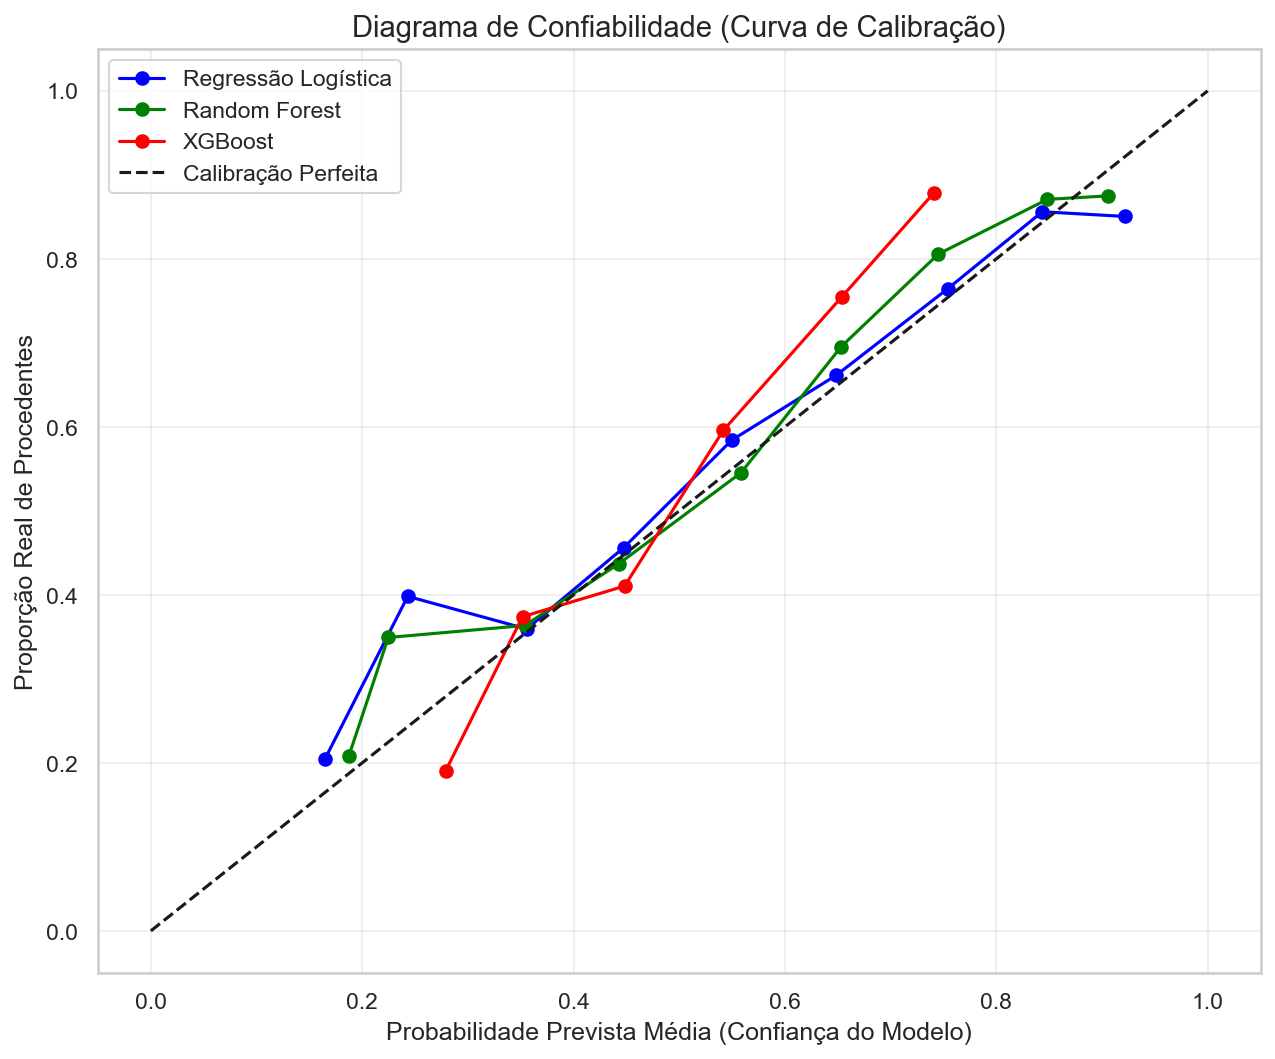

In [63]:

from sklearn.calibration import calibration_curve

plt.figure(figsize=(10, 8), dpi=150)

for nome, y_pr in probs.items():
    prob_true, prob_pred = calibration_curve(y_test, y_pr, n_bins=10, strategy='uniform')
    plt.plot(prob_pred, prob_true, marker='o', label=nome, color=cores[nome])

plt.plot([0, 1], [0, 1], 'k--', label='Calibração Perfeita')
plt.title('Diagrama de Confiabilidade (Curva de Calibração)', fontsize=14)
plt.xlabel('Probabilidade Prevista Média (Confiança do Modelo)', fontsize=12)
plt.ylabel('Proporção Real de Procedentes', fontsize=12)
plt.legend(loc='upper left', fontsize=11)
plt.grid(True, alpha=0.3)
plt.savefig('resultados/curva_calibracao_3_modelos.png', bbox_inches='tight', dpi=300)
plt.show()


## 12. Interpretabilidade: Importância das Variáveis (*Feature Importance* e Coeficientes Lineares)

Um grande desafio da implementação de IA no Direito é a falta de transparência dos algoritmos (*Black Box*). Abaixo, extraímos as lógicas decisórias dos modelos desenvolvidos:
- **Nos Modelos de Árvores (Random Forest e XGBoost):** Visualizamos quais variáveis foram mais decisivas para reduzir a impureza (*Feature Importance* baseada no Índice de Gini), embora a direção do impacto (positivo ou negativo) não seja imediatamente clara.
- **Na Regressão Logística:** Obtemos os coeficientes matemáticos exatos, permitindo afirmar, por exemplo, como o recesso forense ou um tema específico influenciam diretamente a probabilidade de vitória.

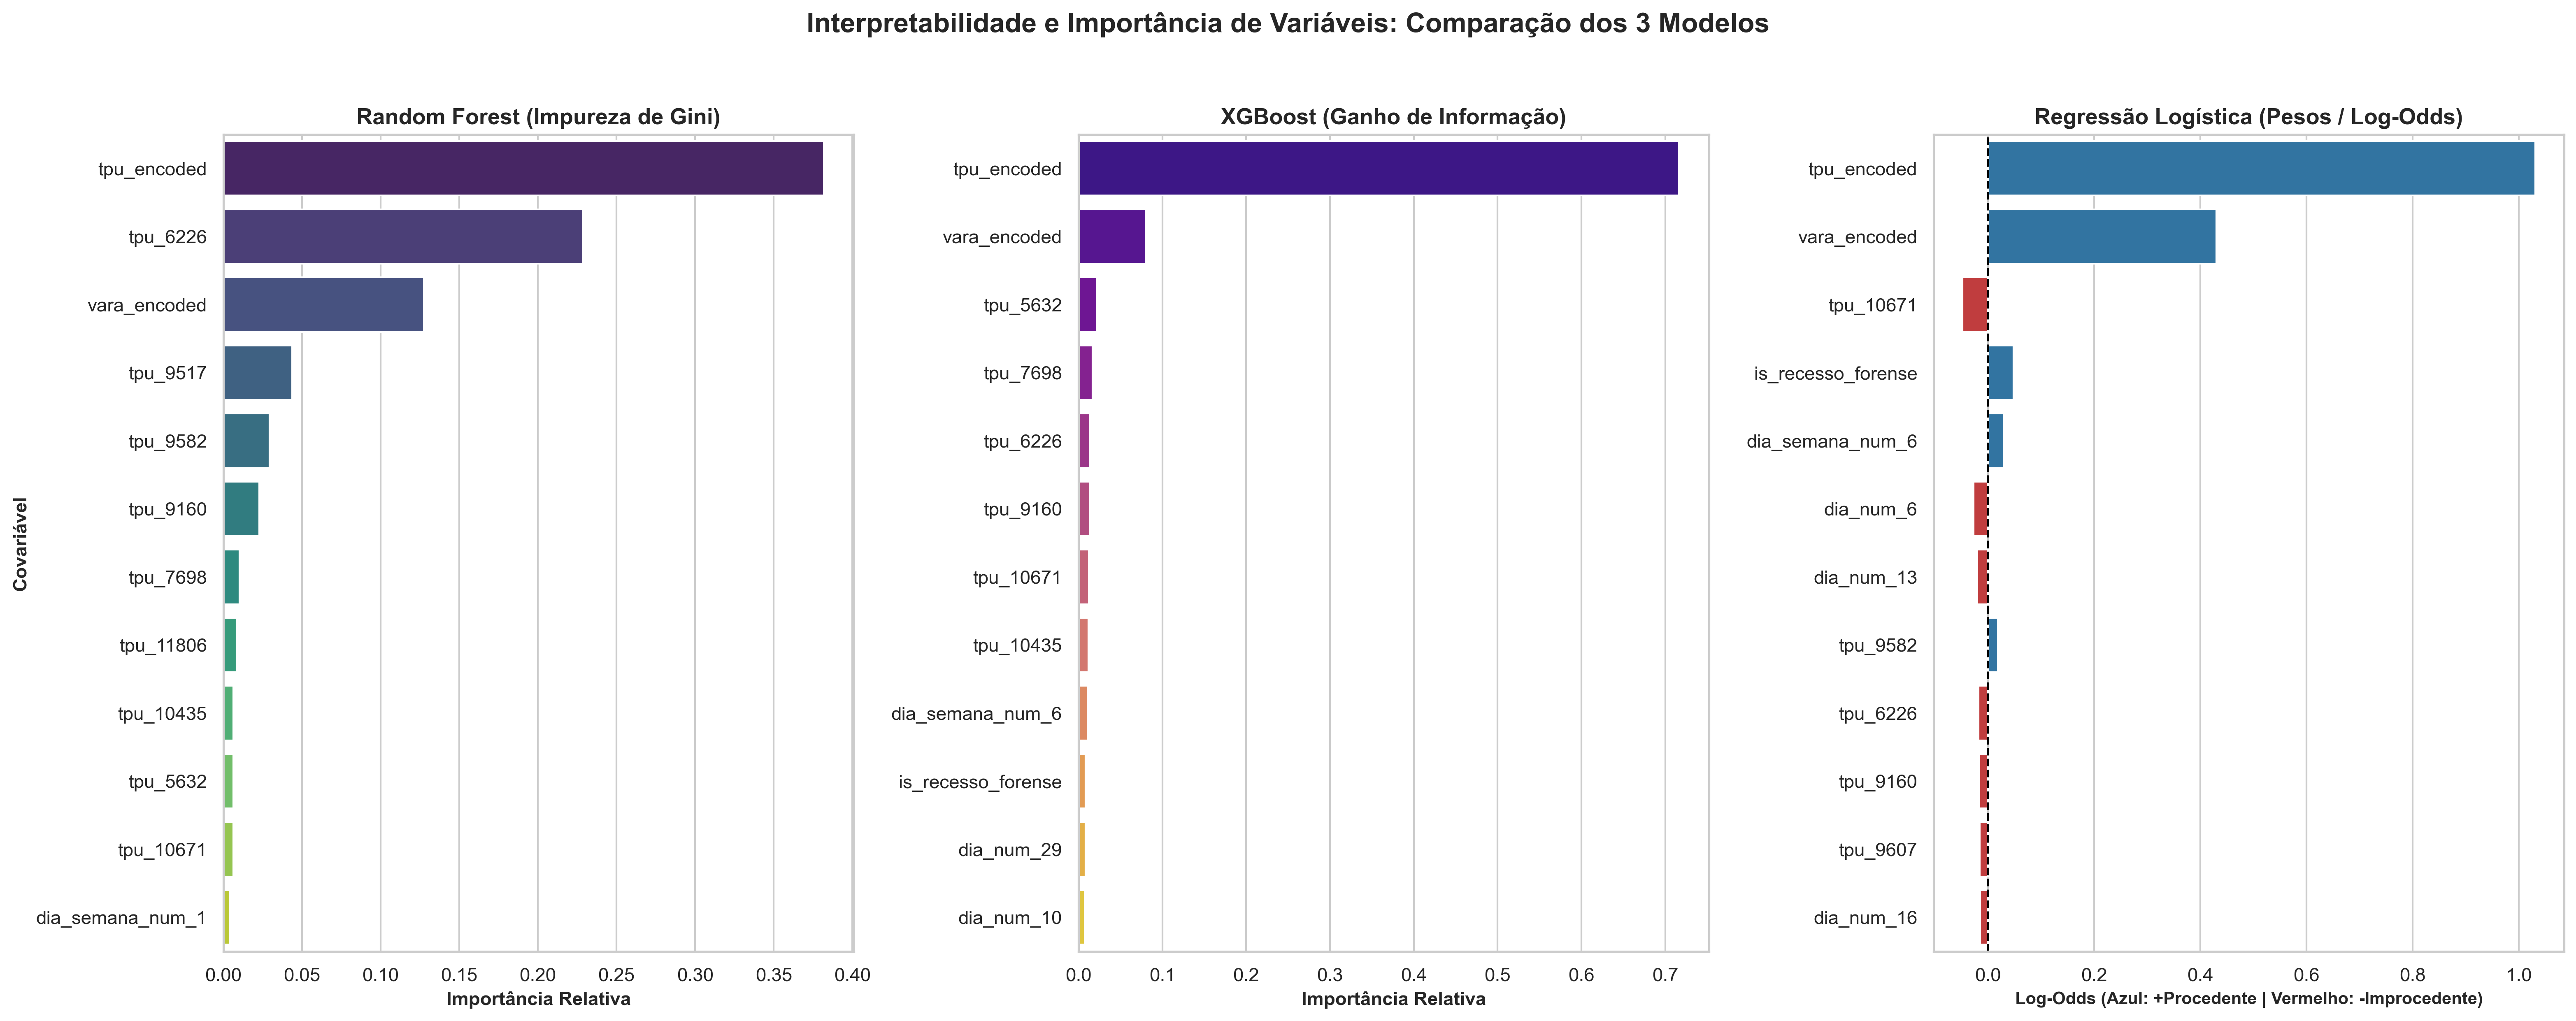

IMPACTO DAS VARIÁVEIS NA REGRESSÃO LOGÍSTICA (MODELO EXPLICÁVEL)
>>> Variáveis de maior impacto POSITIVO (Empurram para PROCEDÊNCIA / Vitória):
           Feature     Peso
       tpu_encoded 1.031243
      vara_encoded 0.430011
is_recesso_forense 0.047979
  dia_semana_num_6 0.030183
          tpu_9582 0.018206

>>> Variáveis de maior impacto NEGATIVO (Empurram para IMPROCEDÊNCIA / Derrota):
   Feature      Peso
  tpu_9160 -0.016594
  tpu_6226 -0.017744
dia_num_13 -0.020081
 dia_num_6 -0.027344
 tpu_10671 -0.048502


In [64]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configurando painel unificado com 3 subplots em alta resolução (300 DPI)
fig, axes = plt.subplots(1, 3, figsize=(21, 8), dpi=300)
fig.suptitle('Interpretabilidade e Importância de Variáveis: Comparação dos 3 Modelos', fontsize=16, fontweight='bold', y=1.03)

# Obter nomes das features pós-TargetEncoder
features_nomes = [c if c not in ['vara', 'assunto_tpu'] else ('vara_encoded' if c == 'vara' else 'tpu_encoded') for c in cols_avancadas]

# 1. Painel 1: Random Forest (Importância Baseada em Gini)
importances_rf = rf_best.named_steps['clf'].feature_importances_
df_imp_rf = pd.DataFrame({'Feature': features_nomes, 'Importance': importances_rf}).sort_values(by='Importance', ascending=False)
sns.barplot(data=df_imp_rf.head(12), x='Importance', y='Feature', hue='Feature', legend=False, ax=axes[0], palette='viridis')
axes[0].set_title('Random Forest (Impureza de Gini)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Importância Relativa', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Covariável', fontsize=11, fontweight='bold')

# 2. Painel 2: XGBoost (Importância Baseada em Ganho)
importances_xgb = xgb_best.named_steps['clf'].feature_importances_
df_imp_xgb = pd.DataFrame({'Feature': features_nomes, 'Importance': importances_xgb}).sort_values(by='Importance', ascending=False)
sns.barplot(data=df_imp_xgb.head(12), x='Importance', y='Feature', hue='Feature', legend=False, ax=axes[1], palette='plasma')
axes[1].set_title('XGBoost (Ganho de Informação)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Importância Relativa', fontsize=11, fontweight='bold')
axes[1].set_ylabel('')

# 3. Painel 3: Regressão Logística (Pesos / Log-Odds com Direção de Impacto)
coefs = pipeline_lr.named_steps['clf'].coef_[0]
df_coefs = pd.DataFrame({'Feature': features_nomes, 'Peso': coefs})
df_coef_plot = df_coefs.copy()
df_coef_plot['Abs_Peso'] = df_coef_plot['Peso'].abs()
df_coef_plot = df_coef_plot.sort_values(by='Abs_Peso', ascending=False).head(12).reset_index(drop=True)

paleta_lr = {row['Feature']: ('tab:blue' if row['Peso'] > 0 else 'tab:red') for _, row in df_coef_plot.iterrows()}
sns.barplot(data=df_coef_plot, x='Peso', y='Feature', hue='Feature', legend=False, ax=axes[2], palette=paleta_lr)
axes[2].axvline(0, color='black', linewidth=1.2, linestyle='--')
axes[2].set_title('Regressão Logística (Pesos / Log-Odds)', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Log-Odds (Azul: +Procedente | Vermelho: -Improcedente)', fontsize=10, fontweight='bold')
axes[2].set_ylabel('')

plt.tight_layout()
plt.savefig('resultados/comparacao_feature_importance_3_modelos.png', bbox_inches='tight', dpi=300)
plt.show()

# Exibição textual dos maiores impactos analíticos
df_coefs_sorted = df_coefs.sort_values(by='Peso', ascending=False)
print('='*70)
print('IMPACTO DAS VARIÁVEIS NA REGRESSÃO LOGÍSTICA (MODELO EXPLICÁVEL)')
print('='*70)
print('>>> Variáveis de maior impacto POSITIVO (Empurram para PROCEDÊNCIA / Vitória):')
print(df_coefs_sorted.head(5).to_string(index=False))
print('')
print('>>> Variáveis de maior impacto NEGATIVO (Empurram para IMPROCEDÊNCIA / Derrota):')
print(df_coefs_sorted.tail(5).to_string(index=False))
print('='*70)


## 13. Diagnósticos de Treinamento e Curvas de Aprendizado

### 13.1 Diagnóstico de Otimização Interna e Convergência (XGBoost)

Antes de considerarmos o tamanho da base de dados, precisamos garantir que o modelo mais complexo (XGBoost) não sofreu de *Overfitting* (memorização dos dados) durante o treinamento.

O gráfico abaixo ilustra a evolução da métrica de erro (*Log Loss*) a cada nova árvore construída. Se a curva correspondente ao conjunto de teste começasse a subir enquanto a do treino continuasse a cair, teríamos um claro indício de sobreajuste. Como ambas decrescem e estabilizam de forma assintótica, confirma-se que o modelo generaliza adequadamente.


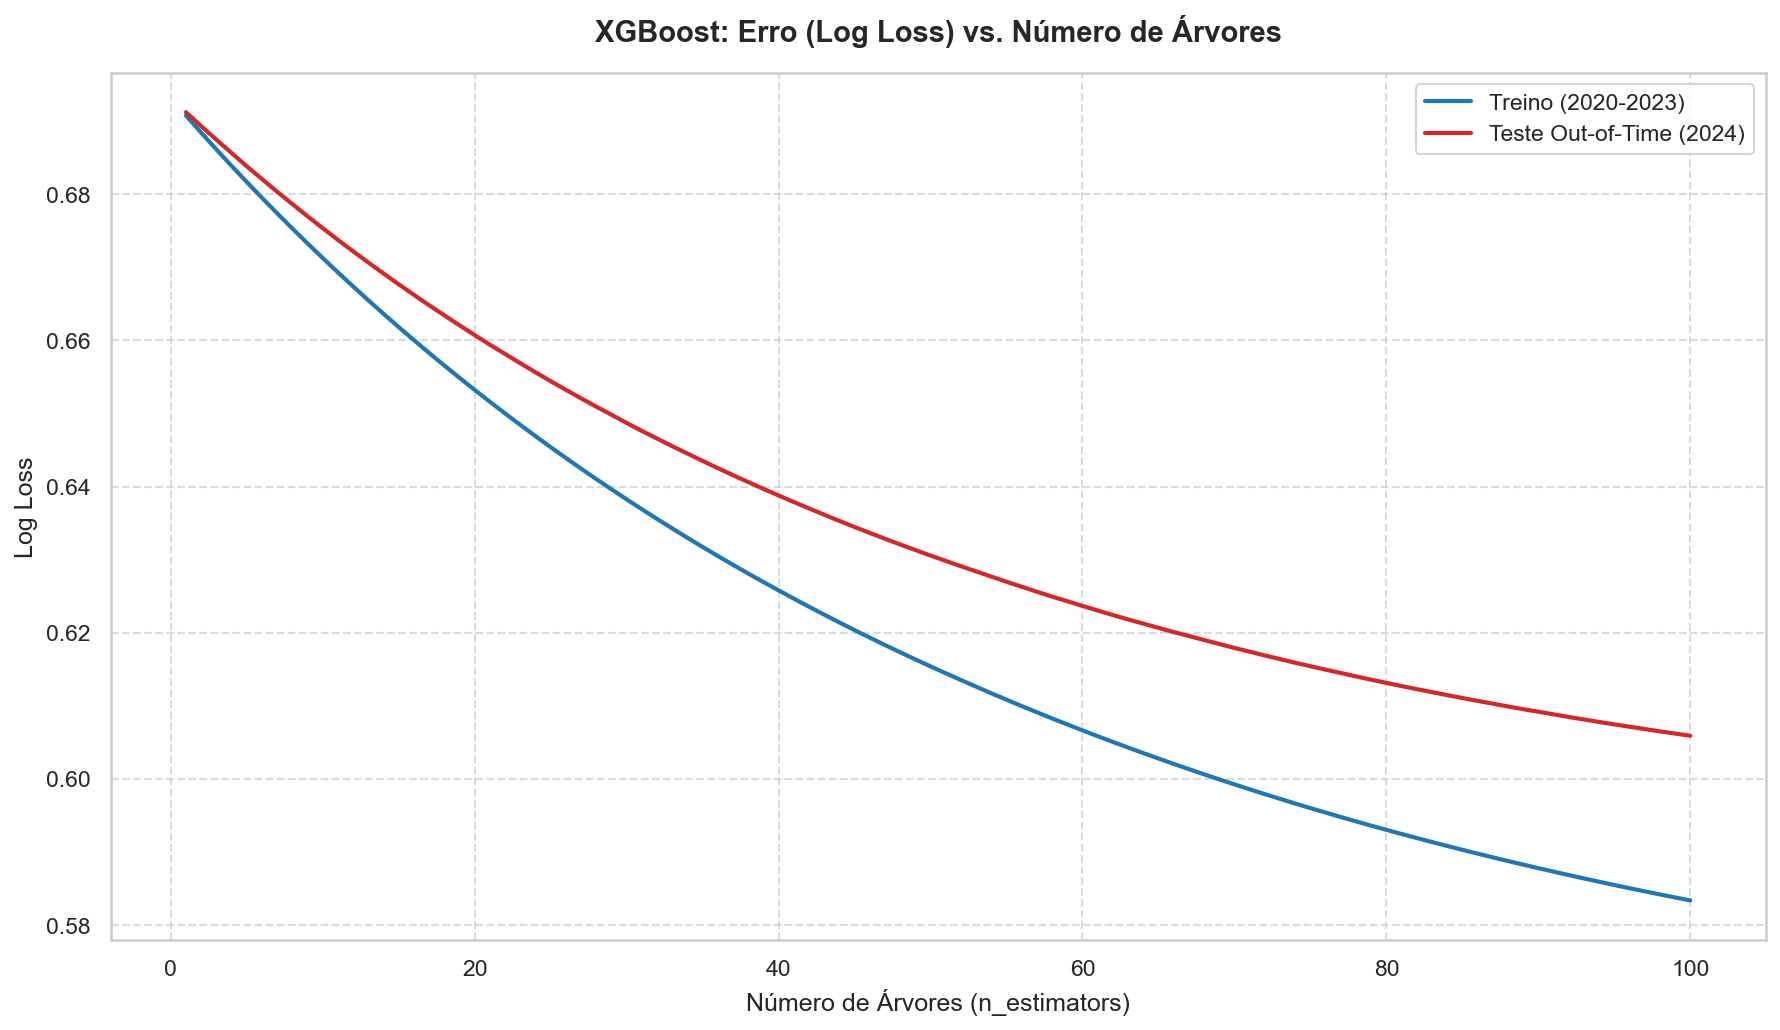

In [65]:
import matplotlib.pyplot as plt
import warnings
from xgboost import XGBClassifier

# Como xgb_best é um Pipeline, extraímos o encoder ajustado e os parâmetros do classificador
encoder = xgb_best.named_steps['target_encoder']
X_treino_encoded = encoder.transform(X_treino_atual, y_treino_atual)
X_teste_encoded = encoder.transform(X_teste_atual)

# Filtramos parâmetros para evitar duplicidade de argumentos e alertas
clf_params = {k: v for k, v in xgb_best.named_steps['clf'].get_params().items() 
              if v is not None and k not in ['early_stopping_rounds', 'use_label_encoder']}
clf_params['eval_metric'] = 'logloss'

# Monitoramento do aprendizado árvore por árvore (Log Loss)
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    xgb_monitor = XGBClassifier(**clf_params)
    xgb_monitor.fit(
        X_treino_encoded, y_treino_atual,
        eval_set=[(X_treino_encoded, y_treino_atual), (X_teste_encoded, y_test)],
        verbose=False
    )

results = xgb_monitor.evals_result()
epochs = len(results['validation_0']['logloss'])
x_axis = range(1, epochs + 1)

plt.figure(figsize=(12, 7), dpi=150)
plt.plot(x_axis, results['validation_0']['logloss'], label='Treino (2020-2023)', linewidth=2, color='tab:blue')
plt.plot(x_axis, results['validation_1']['logloss'], label='Teste Out-of-Time (2024)', linewidth=2, color='tab:red')

plt.title('XGBoost: Erro (Log Loss) vs. Número de Árvores', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Número de Árvores (n_estimators)', fontsize=12)
plt.ylabel('Log Loss', fontsize=12)
plt.legend(loc='upper right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('resultados/xgboost_curva_aprendizado.png', bbox_inches='tight', dpi=300)
plt.show()


### 13.2 Curvas de Aprendizado (Volume de Dados vs. Desempenho Preditivo)

Investigamos agora a questão empírica central: *"Se o Tribunal fornecesse um histórico maior de processos, o desempenho preditivo aumentaria significativamente?"*

O gráfico abaixo exibe a evolução da métrica ROC-AUC à medida que fornecemos volumes progressivos de dados de treino (de 10% a 100%):
* **Gap (Diferença Treino-Validação):** Uma divergência acentuada e persistente ao final da curva indicaria sobreajuste (*Overfitting*).
* **Platô Assintótico:** A estabilização da linha de validação em patamar constante demonstra que o modelo atingiu a capacidade limite de representação com o conjunto atual de atributos estruturados. O incremento de volume de casos brutos não traria ganhos relevantes sem a inclusão de novas fontes de dados (como mineração de peças processuais).


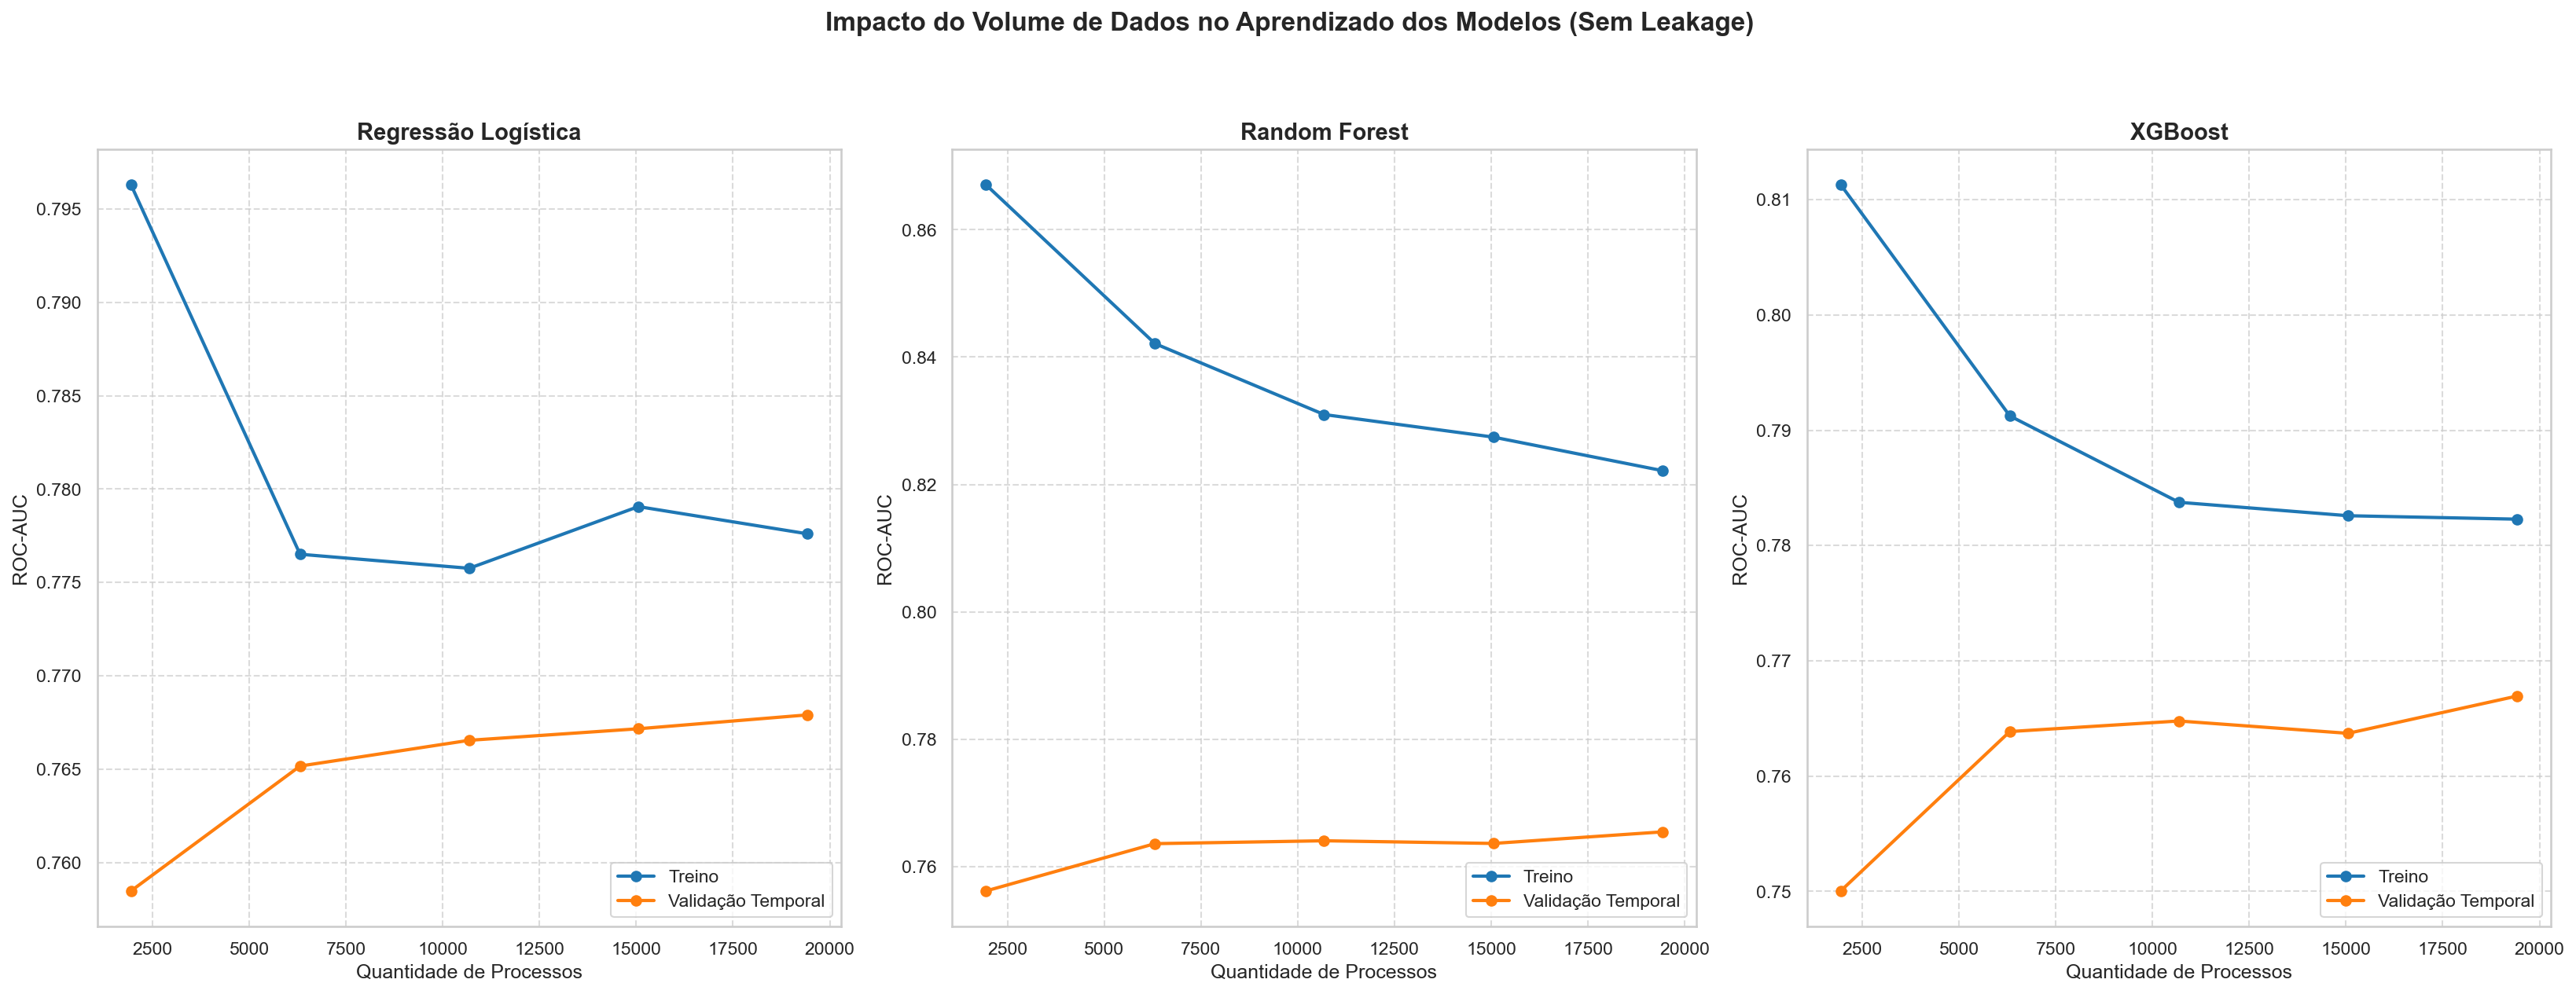

In [66]:
import matplotlib.pyplot as plt
import numpy as np
import gc
from sklearn.model_selection import learning_curve, TimeSeriesSplit

# Coleta de lixo na memoria antes de iniciar as curvas de aprendizado
gc.collect()

fig, axes = plt.subplots(1, 3, figsize=(22, 8), dpi=150)
fig.suptitle('Impacto do Volume de Dados no Aprendizado dos Modelos (Sem Leakage)', fontsize=16, fontweight='bold', y=1.05)

modelos_lc = {
    'Regressão Logística': pipeline_lr,
    'Random Forest': rf_best,
    'XGBoost': xgb_best
}

tscv_lc = TimeSeriesSplit(n_splits=3)

for idx, (nome, modelo) in enumerate(modelos_lc.items()):
    ax = axes[idx]
    
    # Usamos n_jobs=2 para controlar o uso de RAM e evitar estouro de memoria (Kernel Dead)
    train_sizes, train_scores, test_scores = learning_curve(
        modelo, X_treino_atual, y_treino_atual, cv=tscv_lc,
        train_sizes=np.linspace(0.1, 1.0, 5),
        scoring='roc_auc', n_jobs=2
    )
    
    train_scores_mean = np.mean(train_scores, axis=1)
    test_scores_mean = np.mean(test_scores, axis=1)
    
    ax.plot(train_sizes, train_scores_mean, 'o-', color='tab:blue', label='Treino', linewidth=2)
    ax.plot(train_sizes, test_scores_mean, 'o-', color='tab:orange', label='Validação Temporal', linewidth=2)
    ax.set_title(f'{nome}', fontsize=14, fontweight='bold')
    ax.set_xlabel('Quantidade de Processos', fontsize=12)
    ax.set_ylabel('ROC-AUC', fontsize=12)
    ax.legend(loc='lower right')
    ax.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('resultados/curva_aprendizado_volume_dados.png', bbox_inches='tight', dpi=300)
plt.show()


## 14. Extração de Conhecimento Jurídico (Interpretabilidade da Caixa Branca)

Como priorizamos a Regressão Logística com base no Princípio da Navalha de Ockham, ganhamos o grande benefício da **Explicabilidade**.
O gráfico abaixo abre a "Caixa Branca" do modelo e detalha o impacto de cada variável na decisão.
- **Barras Azuis (Direita):** Aumentam a probabilidade de o Consumidor GANHAR (Procedente).
- **Barras Vermelhas (Esquerda):** Aumentam a probabilidade de o Consumidor PERDER (Improcedente).

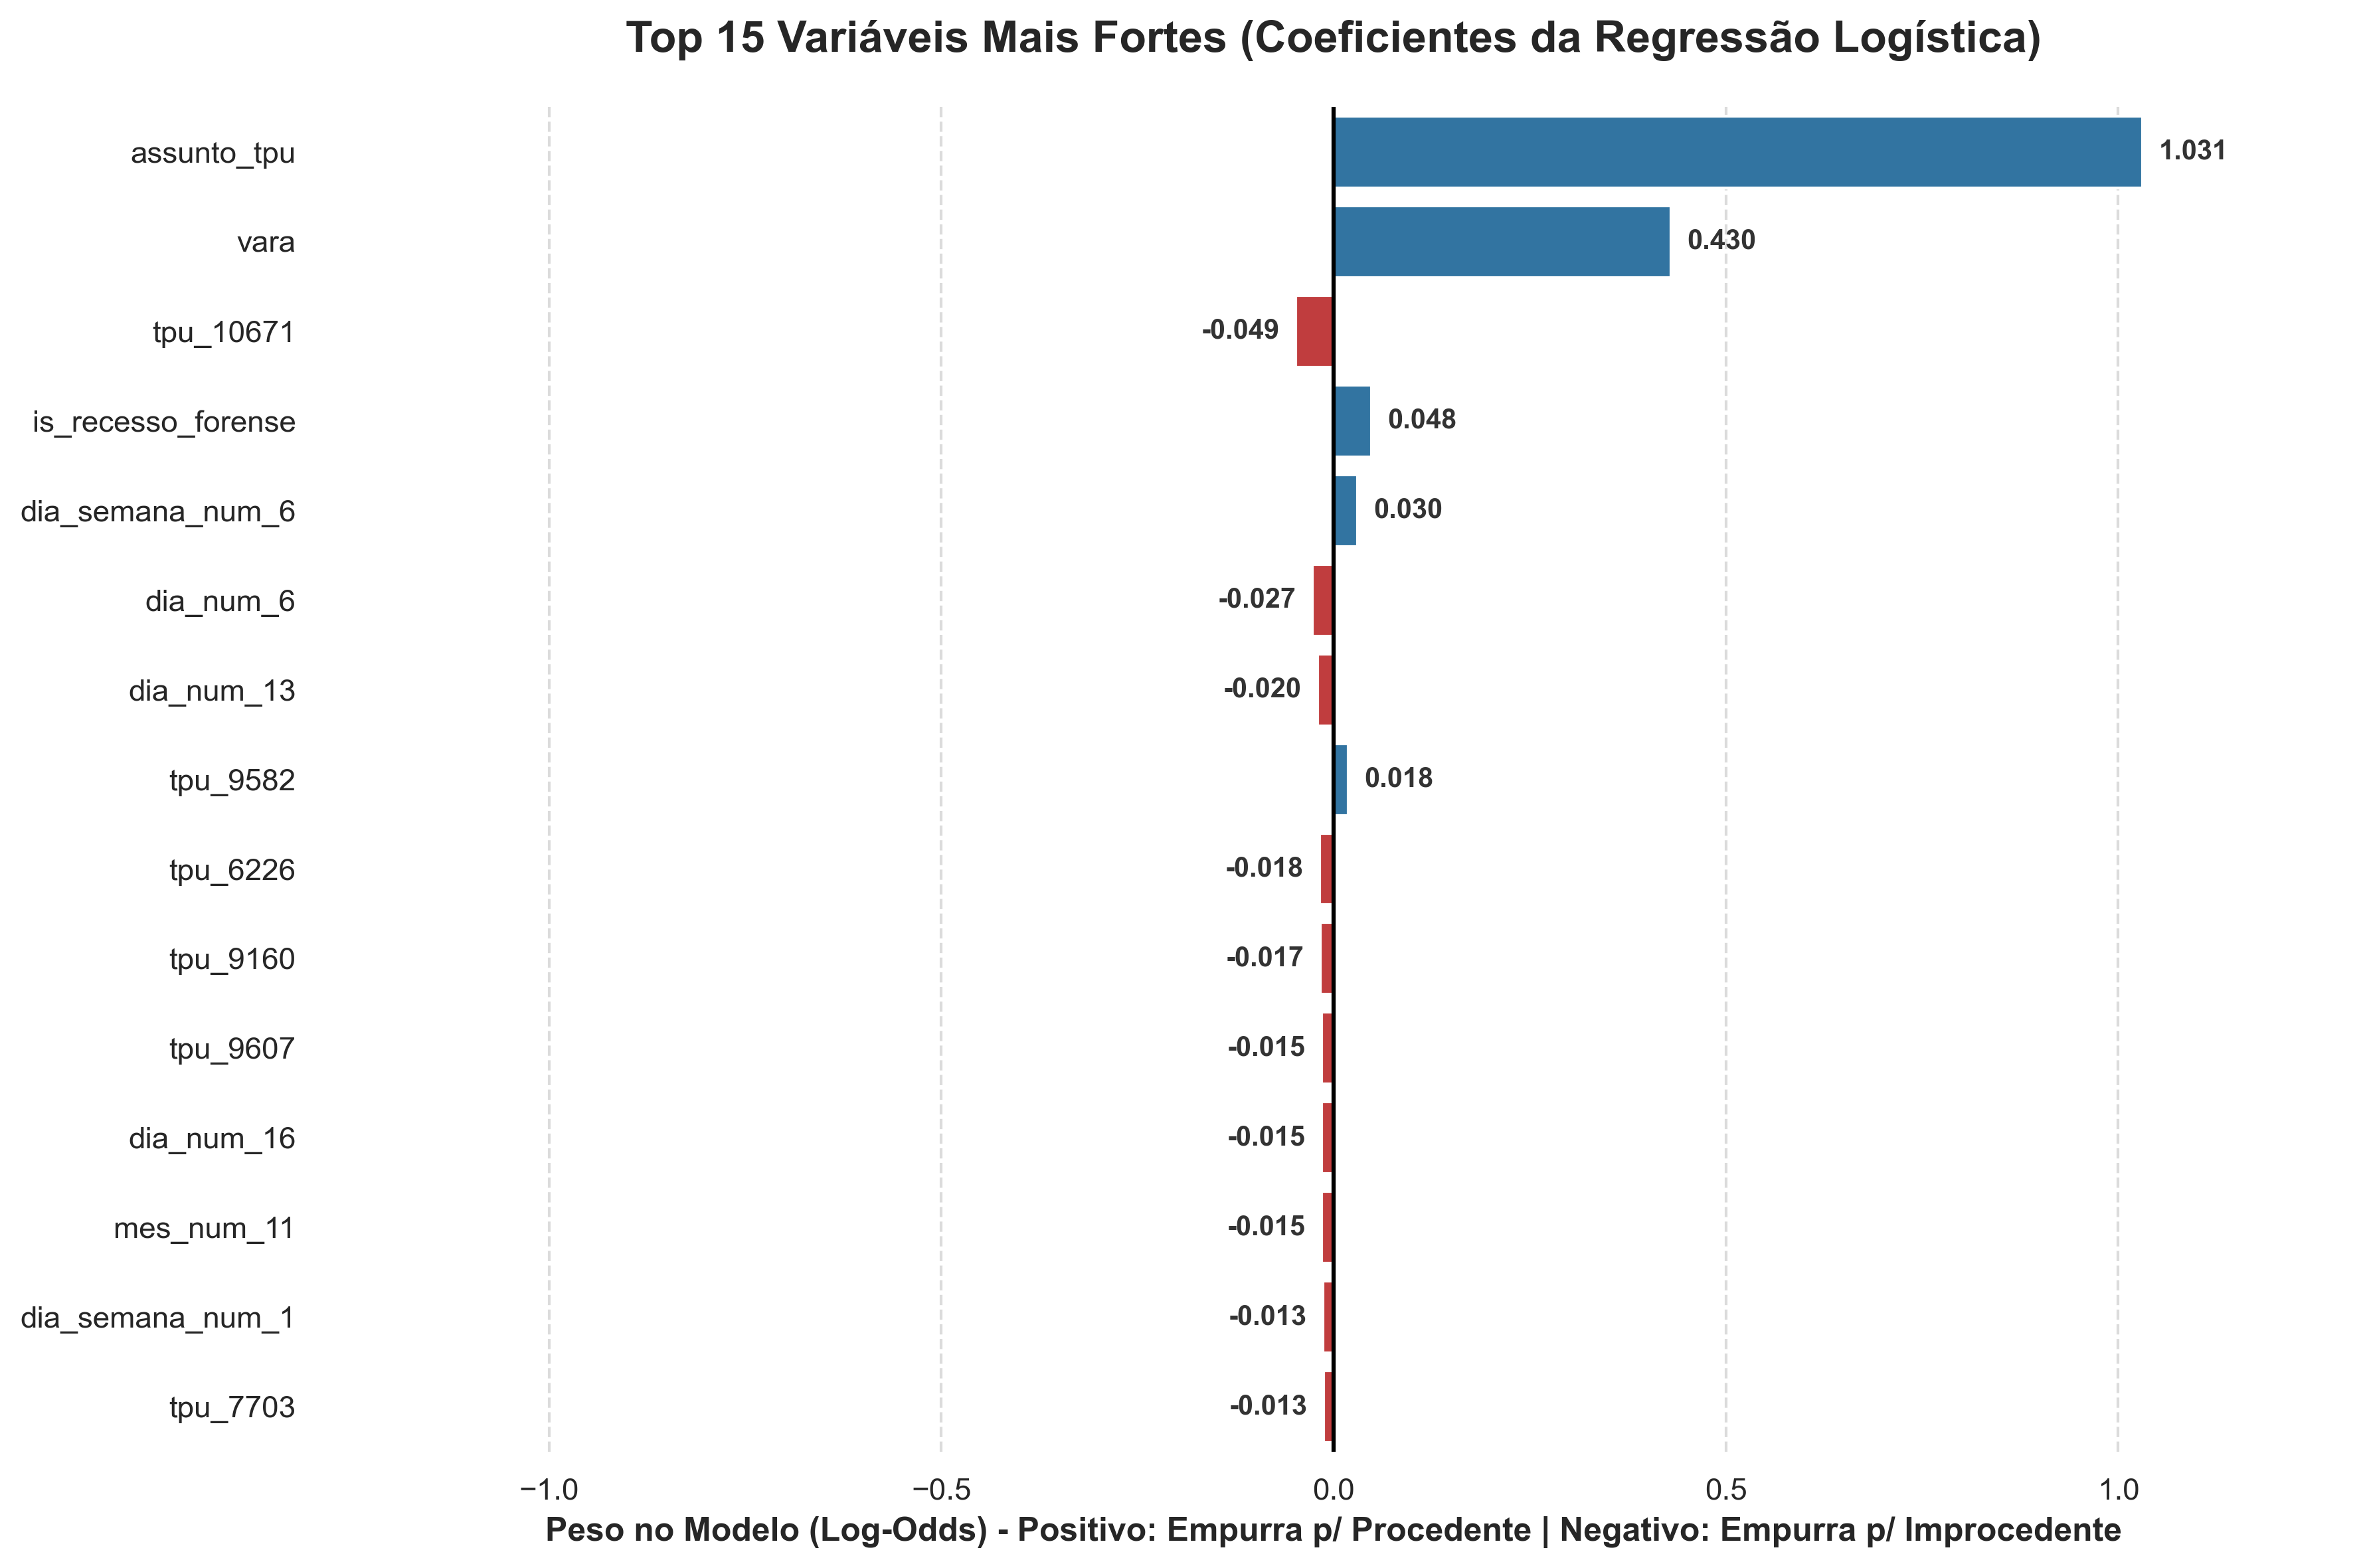

In [67]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

modelo_lr = pipeline_lr.named_steps['clf']
coeficientes = modelo_lr.coef_[0]
features = X_treino_atual.columns

df_coef = pd.DataFrame({'Feature': features, 'Coeficiente': coeficientes})
df_coef['Abs_Coef'] = df_coef['Coeficiente'].abs()
df_coef = df_coef.sort_values(by='Abs_Coef', ascending=False).head(15).reset_index(drop=True)

# Mapeamento de cores seguro
paleta_cores = {row['Feature']: ('tab:blue' if row['Coeficiente'] > 0 else 'tab:red') for _, row in df_coef.iterrows()}

fig, ax = plt.subplots(figsize=(12, 8), dpi=300)
sns.barplot(x='Coeficiente', y='Feature', data=df_coef, palette=paleta_cores, hue='Feature', legend=False, ax=ax)

ax.set_title('Top 15 Variáveis Mais Fortes (Coeficientes da Regressão Logística)', fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Peso no Modelo (Log-Odds) - Positivo: Empurra p/ Procedente | Negativo: Empurra p/ Improcedente', fontsize=12, fontweight='bold')
ax.set_ylabel('')

sns.despine(left=True, bottom=True)
ax.axvline(0, color='black', linewidth=1.5)
ax.grid(axis='x', linestyle='--', alpha=0.7)

# Expandir os limites do eixo X simetricamente para que as barras e textos caibam sem cortar
max_val = df_coef['Abs_Coef'].max()
ax.set_xlim(-max_val * 1.25, max_val * 1.25)

# A forma correta e infalível de anotar (sem usar patches, que quebram com o hue no Seaborn)
for i, row in df_coef.iterrows():
    val = row['Coeficiente']
    # Se positivo, escreve o texto à direita do valor; se negativo, à esquerda
    ha = 'left' if val > 0 else 'right'
    offset = max_val * 0.02 if val > 0 else -max_val * 0.02
    
    ax.text(val + offset, i, f'{val:.3f}', 
            va='center', ha=ha, fontsize=10, fontweight='bold', color='#333333')

plt.tight_layout()
plt.savefig('resultados/top15_coeficientes_regressao_logistica.png', bbox_inches='tight', dpi=300)
plt.show()


## 15. Conclusão e Escolha do Modelo (O Princípio da Parcimônia e Navalha de Ockham)

Ao analisar os resultados consolidados no conjunto de teste *out-of-time* (2024), observamos um **empate técnico estatístico** nas métricas de AUC-ROC e F1-Score entre a **Regressão Logística** e os modelos complexos de *ensemble* (**Random Forest** e **XGBoost**). Isso demonstra que a engenharia criteriosa de atributos de domínio e a codificação adequada dos ciclos temporais permitiram ao modelo linear alcançar paridade de desempenho sem exigir a complexidade não-linear das árvores.

Como ensinam Rafael Izbicki e Tiago Mendonça dos Santos em *Aprendizado de Máquina: Uma Abordagem Estatística* (2020), perante modelos com capacidades preditivas equivalentes, o **Princípio da Parcimônia (Navalha de Ockham)** preconiza a escolha da formulação mais simples e transparente.

No contencioso judicial e na Jurimetria, a **Regressão Logística** se consolida como a escolha ótima: além de mitigar custos computacionais de inferência, ela fornece **interpretabilidade direta e auditabilidade dos coeficientes**, viabilizando a justificação transparente das probabilidades aos magistrados, advogados e jurisdicionados — um requisito ético e regulatório imperativo no Direito.


In [68]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Compilando os resultados finais dinamicamente a partir das predicoes do Teste Out-Of-Time (2024)
lista_resultados = []

for modelo_nome in probs.keys():
    y_p = preds[modelo_nome]
    y_pr = probs[modelo_nome]
    
    lista_resultados.append({
        'Modelo': modelo_nome,
        'Acurácia': accuracy_score(y_test, y_p),
        'Precisão': precision_score(y_test, y_p),
        'Recall': recall_score(y_test, y_p),
        'F1-Score': f1_score(y_test, y_p),
        'ROC-AUC': roc_auc_score(y_test, y_pr)
    })

df_results = pd.DataFrame(lista_resultados).set_index('Modelo')

# Aplicando o Heatmap com visual nitido adaptado ao Tema Escuro / Claro
styled_df = (
    df_results.style
    .background_gradient(cmap='Blues', axis=0)
    .format('{:.4f}')
    .set_caption('Comparação de Métricas Consolidadas (Teste Out-of-Time 2024)')
    .set_table_styles([
        {
            'selector': 'caption',
            'props': [
                ('color', '#38bdf8'),
                ('font-size', '16px'),
                ('font-weight', 'bold'),
                ('text-align', 'left'),
                ('padding-bottom', '8px')
            ]
        },
        {
            'selector': 'th',
            'props': [
                ('background-color', '#1e293b'),
                ('color', '#f8fafc'),
                ('font-weight', 'bold'),
                ('text-align', 'center'),
                ('padding', '8px 14px'),
                ('border', '1px solid #334155')
            ]
        },
        {
            'selector': 'th.row_heading',
            'props': [
                ('background-color', '#1e293b'),
                ('color', '#f8fafc'),
                ('font-weight', 'bold'),
                ('text-align', 'left'),
                ('padding', '8px 14px'),
                ('border', '1px solid #334155')
            ]
        },
        {
            'selector': 'td',
            'props': [
                ('padding', '8px 14px'),
                ('text-align', 'center'),
                ('border', '1px solid #94a3b8')
            ]
        }
    ])
)

styled_df


,Acurácia,Precisão,Recall,F1-Score,ROC-AUC
Modelo,,,,,
Regressão Logística,0.6762,0.6787,0.8757,0.7647,0.7313
Random Forest,0.6825,0.6907,0.8542,0.7638,0.7313
XGBoost,0.6887,0.7043,0.8307,0.7623,0.7332
